# 03. EDA: patrones de demanda para decidir dónde y cuándo se necesita apoyo logístico

**Puntos de la rúbrica:** b (descriptiva, distribuciones, patrones, variable objetivo y características) y c (análisis preliminar y contexto adicional).

## La pregunta que guía el análisis

> **¿Qué estaciones de la troncal de TransMilenio requieren refuerzo de personal de apoyo para ordenar el ingreso de usuarios, según su demanda por franja horaria?**

## ¿Existe la variable objetivo?

**No viene en los datos: hay que construirla.** Cada fila de la base es *una validación*; lo que queremos explicar y predecir es **cuánta gente entra a una estación en una hora**. Entonces la variable objetivo es:

> **`validaciones` = número de validaciones por estación, fecha y hora** (se obtiene contando filas).

Es un **conteo** (entero ≥ 0) y se observa directamente, así que más adelante el modelo se puede evaluar contra datos reales. La "necesidad de personal" en sí **no está en los datos**: se infiere de la demanda (se explica más adelante).

## Hilo conductor (de lo general a lo específico)

| # | Pregunta | Qué se hace |
|---|---|---|
| 1 | ¿Cuál es la unidad de trabajo? | Construir la tabla estación–fecha–hora (la variable objetivo) |
| 2 | ¿Todos los días se comportan igual? | Festivo, fines de semana y semanas: ¿analizamos solo los días hábiles? |
| 3 | ¿Cómo se distribuye la demanda en el día? | Distribución por hora, boxplots con y sin fines de semana |
| 4 | ¿Dónde se concentra? | Estaciones, formas horarias y tipos de estación |
| 5 | ¿Quiénes entran? | Perfiles de usuario y tarifas por hora |
| 6 | ¿Cómo se mueve la demanda en la ciudad? | Mapa por franjas horarias |
| 7 | ¿La gente vuelve en TransMilenio? | Viaje de ida y de regreso por tarjeta |
| 8 | ¿Qué se relaciona con qué? | Correlaciones (Pearson y Spearman), varianzas y covarianzas |
| 9 | ¿Qué hipótesis salen? | Patrones → hipótesis → pregunta analítica |

> El Teorema del Límite Central se verifica en un **notebook aparte** (04), con la hora de la validación.
> Se avanza **por partes**: cada bloque se revisa antes del siguiente.

## 1. La tabla de trabajo: una fila por estación, fecha y hora

Se pasa de **31.5 millones de filas** (una por validación) a una tabla de unas **60 mil filas**: para cada estación, fecha y hora, cuántas validaciones hubo. Aquí se aplican las decisiones de limpieza del notebook 02:

- la fecha y la hora salen de `Fecha_Transaccion` (la fecha real, no la del archivo),
- el código de estación (5 dígitos) se separa del nombre,
- se marcan los días **completos** y los **tipos de día** (hábil, sábado, domingo, festivo) construidos desde la fecha.

No se pierde ninguna validación: la suma de la tabla debe dar exactamente las 31,530,646.

In [1]:
# QUÉ HACE: construye la variable objetivo: cuenta las validaciones por estación, fecha y hora, y le agrega el tipo de día.
# CÓMO: Dask lee solo 2 columnas del consolidado, saca fecha, hora y código de estación del texto y cuenta filas por grupo (groupby + size).
# QUÉ MIRAR: la suma de la tabla = 31,530,646 (no se pierde nada); ~60 mil filas; 154 estaciones; columnas fecha, hora, código y validaciones.
import time, warnings
import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
dask.config.set(scheduler='threads', num_workers=3)

VALIDACIONES = Path('../data/processed/validaciones')
PANEL = Path('../data/processed/panel_estacion_hora.parquet')
FIGS = Path('../docs/figs'); FIGS.mkdir(parents=True, exist_ok=True)
FESTIVOS = ['2026-08-07']                      # Batalla de Boyacá (único festivo de las fechas)

val = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion', 'Estacion_Parada'])
N = len(val)

t0 = time.perf_counter()
base = val.assign(fecha=val['Fecha_Transaccion'].str[:10],
                  hora=val['Fecha_Transaccion'].str[11:13].astype('int64'),
                  cod_estacion=val['Estacion_Parada'].str[1:6])        # "(08000) Portal Tunal" -> "08000"
panel = (base.groupby(['cod_estacion', 'fecha', 'hora']).size()
             .compute().rename('validaciones').reset_index())
print(f"Tabla construida en {time.perf_counter() - t0:.0f} s")

assert panel['validaciones'].sum() == N, 'se perdieron validaciones'
assert panel['cod_estacion'].str.fullmatch(r'\d{5}').all(), 'hay códigos de estación raros'
print(f"{len(panel):,} filas | {panel['cod_estacion'].nunique()} estaciones | {panel['fecha'].nunique()} fechas | suma = {panel['validaciones'].sum():,}")
panel.head()

Tabla construida en 11 s
60,119 filas | 154 estaciones | 24 fechas | suma = 31,530,646


,cod_estacion,fecha,hora,validaciones
0,02000,2026-08-03,4,584
1,02000,2026-08-03,5,4584
2,02000,2026-08-03,6,9262
3,02000,2026-08-03,7,9362
4,02000,2026-08-03,8,6139


In [2]:
# QUÉ HACE: arma el calendario (una fila por fecha con su tipo de día), se lo agrega a la tabla de trabajo y la guarda.
# CÓMO: tipo_dia sale de la fecha: festivo si está en FESTIVOS; si no, sábado, domingo o hábil según el día de la semana; completo = más de 10,000 validaciones.
# QUÉ MIRAR: 24 fechas: 21 completas (14 hábiles, 3 sábados, 3 domingos, 1 festivo) y 3 colas de medianoche que no se usan.
DIAS = ['lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo']

calendario = panel.groupby('fecha')['validaciones'].sum().to_frame()
calendario.index = pd.to_datetime(calendario.index)
dow = calendario.index.dayofweek
calendario['día'] = [DIAS[d] for d in dow]
calendario['tipo_dia'] = np.where(calendario.index.isin(pd.to_datetime(FESTIVOS)), 'festivo',
                          np.where(dow == 5, 'sábado', np.where(dow == 6, 'domingo', 'hábil')))
calendario['completo'] = calendario['validaciones'] > 10_000
calendario['semana'] = (calendario.index - pd.to_timedelta(dow, unit='D')).strftime('%Y-%m-%d')   # lunes de esa semana

tipo = dict(zip(calendario.index.strftime('%Y-%m-%d'), calendario['tipo_dia']))
completo = dict(zip(calendario.index.strftime('%Y-%m-%d'), calendario['completo']))
panel['tipo_dia'] = panel['fecha'].map(tipo)
panel['completo'] = panel['fecha'].map(completo)
panel.to_parquet(PANEL, index=False)

print(calendario[calendario['completo']].groupby('tipo_dia').size().rename('días completos').to_frame().T.to_string())
calendario.index.name = 'fecha'
calendario

tipo_dia        domingo  festivo  hábil  sábado
días completos        3        1     14       3


,validaciones,día,tipo_dia,completo,semana
fecha,,,,,
2026-08-03,1817358,lunes,hábil,True,2026-08-03
2026-08-04,1879861,martes,hábil,True,2026-08-03
2026-08-05,1893706,miércoles,hábil,True,2026-08-03
2026-08-06,1837051,jueves,hábil,True,2026-08-03
2026-08-07,525834,viernes,festivo,True,2026-08-03
2026-08-08,1062203,sábado,sábado,True,2026-08-03
2026-08-09,516447,domingo,domingo,True,2026-08-03
2026-08-10,1751957,lunes,hábil,True,2026-08-10
2026-08-11,1832549,martes,hábil,True,2026-08-10


## 2. ¿Todos los días se comportan igual?

Antes de analizar la demanda hay que decidir **qué días se analizan juntos**. Se comparan tres cosas:

1. **El total de cada día** (¿cuánto cambian el festivo y los fines de semana frente a un día hábil?).
2. **La curva por hora** de cada tipo de día (¿cambia solo el volumen, o también la forma?).
3. **Semana por semana**, para ver el festivo en su contexto (la semana del 3 al 9 de agosto tiene el festivo del viernes 7).

Colores fijos en todo el notebook: **hábil** azul, **sábado** naranja, **domingo** verde, **festivo** rojo (con línea punteada).

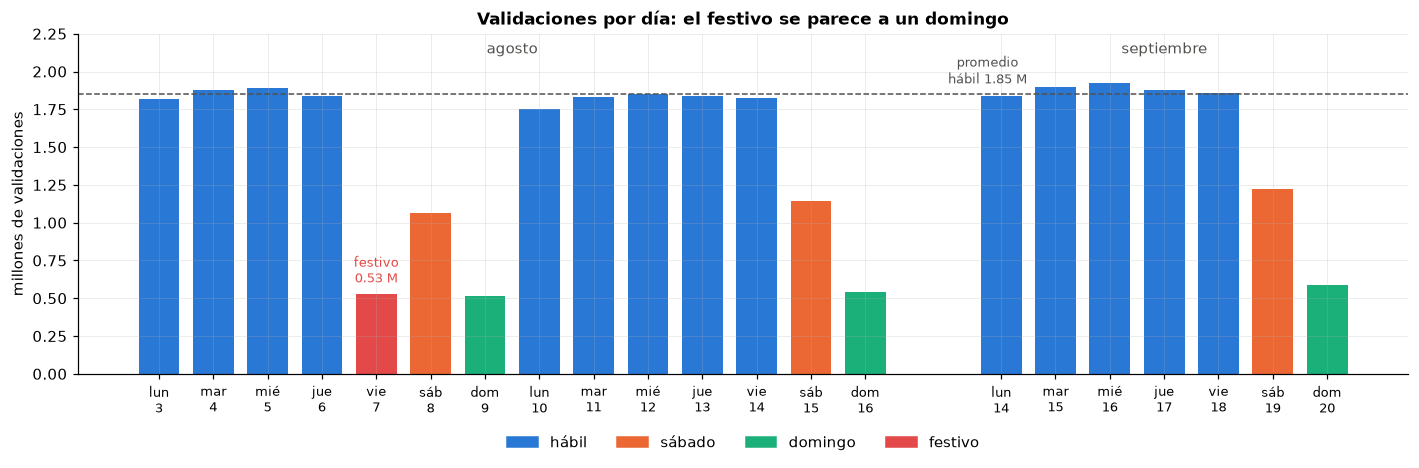

In [3]:
# QUÉ HACE: define los colores y el estilo de todas las gráficas, y dibuja el total de validaciones de cada día completo.
# CÓMO: una barra por día, coloreada por tipo de día; una línea punteada marca el promedio de un día hábil; el hueco del medio es el mes sin datos (17-ago a 13-sep).
# QUÉ MIRAR: el festivo (barra roja) se parece a un domingo, no a un día hábil; los sábados están a mitad de camino; los días hábiles son parecidos entre sí.
COL = {'hábil': '#2a78d6', 'sábado': '#eb6834', 'domingo': '#1baf7a', 'festivo': '#e34948'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'legend.frameon': False})

completos = calendario[calendario['completo']].copy()
x = np.arange(len(completos), dtype=float)
x[completos.index >= pd.Timestamp('2026-09-14')] += 1.5          # hueco entre agosto y septiembre
promedio_habil = completos.loc[completos['tipo_dia'] == 'hábil', 'validaciones'].mean()

fig, ax = plt.subplots(figsize=(13, 4.4))
ax.bar(x, completos['validaciones'] / 1e6, color=[COL[t] for t in completos['tipo_dia']], width=0.75)
ax.axhline(promedio_habil / 1e6, color='#52514e', lw=1, ls='--')
ax.text(15.25, promedio_habil / 1e6 + 0.04, f"promedio\nhábil {promedio_habil / 1e6:.2f} M", ha='center', va='bottom', fontsize=8.5, color='#52514e')
ax.set_xticks(x)
ax.set_xticklabels([f"{d[:3]}\n{f.day}" for d, f in zip(completos['día'], completos.index)], fontsize=8.5)
ax.text(6.5, 2.12, 'agosto', ha='center', color='#52514e'); ax.text(x[14:].mean(), 2.12, 'septiembre', ha='center', color='#52514e')
festivo = completos[completos['tipo_dia'] == 'festivo']
xf = x[list(completos.index).index(festivo.index[0])]
ax.text(xf, festivo['validaciones'].iloc[0] / 1e6 + 0.05, f"festivo\n{festivo['validaciones'].iloc[0] / 1e6:.2f} M", ha='center', va='bottom', fontsize=8.5, color=COL['festivo'])
ax.set_ylabel('millones de validaciones'); ax.set_ylim(0, 2.25)
ax.set_title('Validaciones por día: el festivo se parece a un domingo')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
ax.legend(handles, COL.keys(), ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.14))
plt.tight_layout(); plt.savefig(FIGS / '03_total_por_dia.png', bbox_inches='tight'); plt.show()

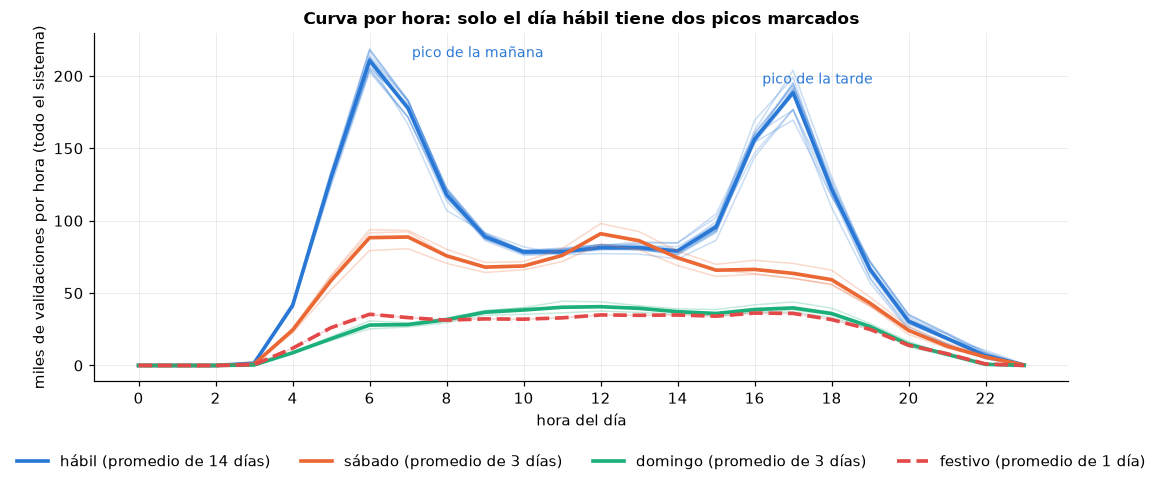

In [4]:
# QUÉ HACE: dibuja la curva por hora del sistema completo para cada tipo de día (cada día en línea fina y el promedio del tipo en línea gruesa).
# CÓMO: suma las validaciones de todas las estaciones por fecha y hora; luego promedia los días del mismo tipo.
# QUÉ MIRAR: el día hábil tiene DOS picos (mañana y tarde); sábado, domingo y festivo son planos y bajos; el festivo (punteada roja) sigue la forma del domingo.
dh = (panel[panel['completo']].groupby(['fecha', 'hora'])['validaciones'].sum()
      .unstack(fill_value=0).reindex(columns=range(24), fill_value=0))
dh.index = pd.to_datetime(dh.index)
tipo_por_dia = calendario.loc[dh.index, 'tipo_dia']

fig, ax = plt.subplots(figsize=(11, 4.6))
for t in COL:
    dias_t = dh[tipo_por_dia == t]
    for _, fila in dias_t.iterrows():
        ax.plot(range(24), fila / 1e3, color=COL[t], alpha=0.25, lw=1)
    ax.plot(range(24), dias_t.mean() / 1e3, color=COL[t], lw=2.4, ls='--' if t == 'festivo' else '-',
            label=f"{t} (promedio de {len(dias_t)} {'día' if len(dias_t) == 1 else 'días'})")
ax.text(7.1, dh[tipo_por_dia == 'hábil'].mean().max() / 1e3, 'pico de la mañana', color=COL['hábil'], fontsize=9, va='bottom')
ax.text(16.2, dh[tipo_por_dia == 'hábil'].mean()[17] / 1e3 + 4, 'pico de la tarde', color=COL['hábil'], fontsize=9, va='bottom')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hora del día'); ax.set_ylabel('miles de validaciones por hora (todo el sistema)')
ax.set_title('Curva por hora: solo el día hábil tiene dos picos marcados')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.17))
plt.tight_layout(); plt.savefig(FIGS / '03_curva_por_tipo_dia.png', bbox_inches='tight'); plt.show()

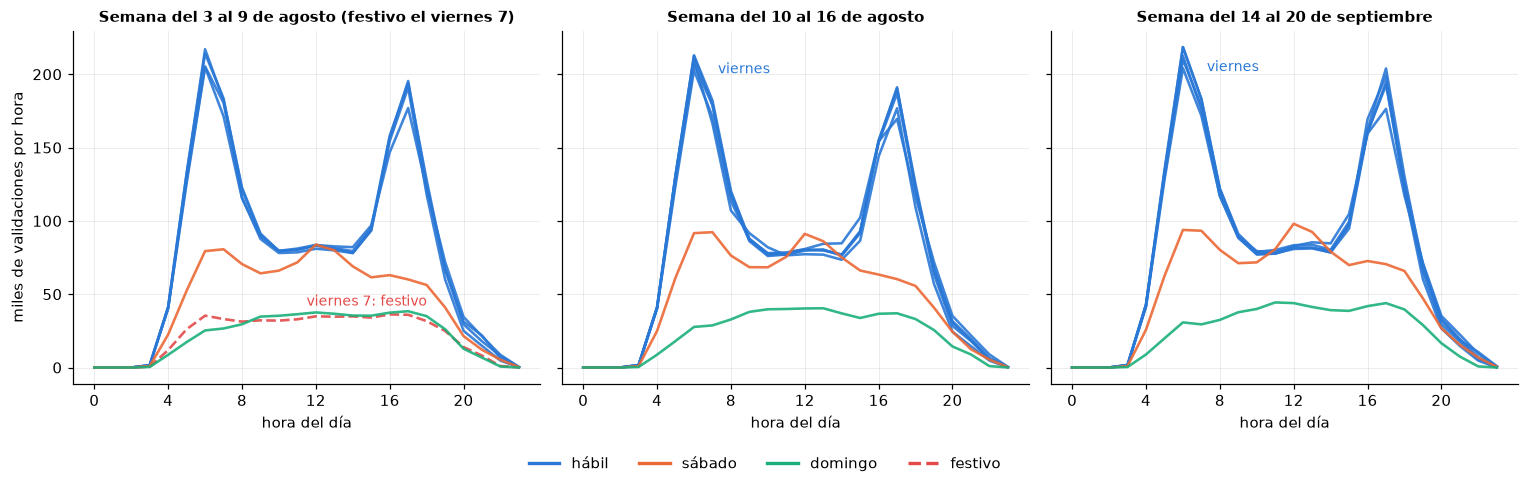

In [5]:
# QUÉ HACE: dibuja la curva por hora de cada día, semana por semana (un panel por semana), para ver el festivo en su contexto.
# CÓMO: tres paneles con la misma escala vertical; cada línea es un día de esa semana, coloreada por tipo de día.
# QUÉ MIRAR: en la semana del 3 de agosto el viernes (rojo punteado) cae al nivel de un domingo; en las otras dos semanas el viernes es un día hábil normal; las tres semanas se parecen en forma.
semanas = [('2026-08-03', 'Semana del 3 al 9 de agosto (festivo el viernes 7)'),
           ('2026-08-10', 'Semana del 10 al 16 de agosto'),
           ('2026-09-14', 'Semana del 14 al 20 de septiembre')]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, (lunes, titulo) in zip(axes, semanas):
    dias_semana = calendario[(calendario['semana'] == lunes) & calendario['completo']]
    for fecha, fila in dias_semana.iterrows():
        ax.plot(range(24), dh.loc[fecha] / 1e3, color=COL[fila['tipo_dia']], lw=1.7,
                ls='--' if fila['tipo_dia'] == 'festivo' else '-', alpha=0.9)
        if fila['tipo_dia'] == 'festivo':
            ax.text(11.5, dh.loc[fecha].max() / 1e3 + 6, 'viernes 7: festivo', color=COL['festivo'], fontsize=9)
        if fila['día'] == 'viernes' and fila['tipo_dia'] == 'hábil':
            ax.text(7.3, dh.loc[fecha].max() / 1e3 - 2, 'viernes', color=COL['hábil'], fontsize=9)
    ax.set_title(titulo, fontsize=10); ax.set_xticks(range(0, 24, 4)); ax.set_xlabel('hora del día')
axes[0].set_ylabel('miles de validaciones por hora')
handles = [plt.Line2D([0], [0], color=c, lw=2.2, ls='--' if t == 'festivo' else '-') for t, c in COL.items()]
fig.legend(handles, COL.keys(), ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(FIGS / '03_curvas_por_semana.png', bbox_inches='tight'); plt.show()

In [6]:
# QUÉ HACE: resume en una tabla cómo cambia cada tipo de día frente al día hábil, y compara los tres viernes (uno festivo y dos normales).
# CÓMO: promedios por tipo de día (validaciones por día, hora pico y qué parte del día cae en esa hora) y los totales de cada viernes.
# QUÉ MIRAR: el sábado tiene ~62 % de la demanda de un hábil, el domingo y el festivo ~30 %; la hora pico del hábil concentra más del día que la de los otros tipos.
resumen_dias = []
for t in ['hábil', 'sábado', 'domingo', 'festivo']:
    dias_t = dh[tipo_por_dia == t]
    curva = dias_t.mean()
    resumen_dias.append({'tipo_dia': t, 'días': len(dias_t),
                         'validaciones_por_día': dias_t.sum(axis=1).mean(),
                         'hora_pico': int(curva.idxmax()), 'validaciones_en_hora_pico': curva.max(),
                         '% del día en la hora pico': curva.max() / curva.sum() * 100})
resumen_dias = pd.DataFrame(resumen_dias).set_index('tipo_dia')
resumen_dias['% frente a un día hábil'] = resumen_dias['validaciones_por_día'] / resumen_dias.loc['hábil', 'validaciones_por_día'] * 100
display(resumen_dias.round(1))

viernes = calendario[(calendario['día'] == 'viernes') & calendario['completo']][['validaciones', 'tipo_dia']].copy()
viernes['% frente al viernes normal'] = viernes['validaciones'] / viernes.loc[viernes['tipo_dia'] == 'hábil', 'validaciones'].mean() * 100
print('\nLos tres viernes:')
viernes.round(1)

,días,validaciones_por_día,hora_pico,validaciones_en_hora_pico,% del día en la hora pico,% frente a un día hábil
tipo_dia,,,,,,
hábil,14,1852255.3,6,210691.6,11.4,100.0
sábado,3,1142830.3,12,91012.7,8.0,61.7
domingo,3,548140.7,12,40596.0,7.4,29.6
festivo,1,525834.0,16,36209.0,6.9,28.4



Los tres viernes:


,validaciones,tipo_dia,% frente al viernes normal
fecha,,,
2026-08-07,525834,festivo,28.5
2026-08-14,1827777,hábil,99.1
2026-09-18,1860400,hábil,100.9


### Lectura de la sección 2

- **Los días no son iguales.** Un sábado tiene ~62 % de las validaciones de un día hábil; el domingo y el festivo, ~30 %.
- **El festivo se comporta como un domingo**, no como un viernes: el viernes 7 de agosto (526 mil) es 28 % de un viernes normal (~1,84 M), mientras que los viernes 14 de agosto y 18 de septiembre quedan en 99 % y 101 %.
- **La forma de la curva también cambia, no solo el volumen.** Solo el día hábil tiene dos picos (6 a. m. y 5 p. m.) y su hora pico concentra 11,4 % del día; sábado, domingo y festivo son curvas bajas y casi planas (la hora pico concentra 7–8 %).
- **Las tres semanas son parecidas entre sí:** las 14 curvas de los días hábiles casi se superponen, así que ninguna semana es "rara".

**Decisión:** el objetivo es anticipar dónde y cuándo se necesita apoyo logístico en horas de alta presión, y esa presión ocurre en los días hábiles. Mezclar fines de semana y festivo con los hábiles inflaría la variación artificialmente (en la sección 3 se comprueba con boxplots). **Se analizan los 14 días hábiles de las tres semanas**; sábado, domingo y festivo quedan como contexto y como posible extensión (modelo aparte por tipo de día).

## 3. ¿Cómo se distribuye la demanda a lo largo del día?

Desde aquí se trabaja **solo con los 14 días hábiles** (decisión de la sección 2). Se mira la demanda de dos maneras:

1. **La distribución de la hora de la validación** (minuto a minuto): ¿qué forma tienen los dos picos? La idea del profesor es que cada pico parece una campana (sube hasta un máximo y luego baja). Se mide con asimetría y curtosis, y se deja la verificación formal (Teorema del Límite Central) para el anexo.
2. **Boxplots por hora** del total del sistema, **con y sin fines de semana**, para ver por qué conviene quitarlos.

14 días hábiles: 2026-08-03 a 2026-09-18


Conteo por minuto en 12 s | validaciones en hábiles: 25,931,574


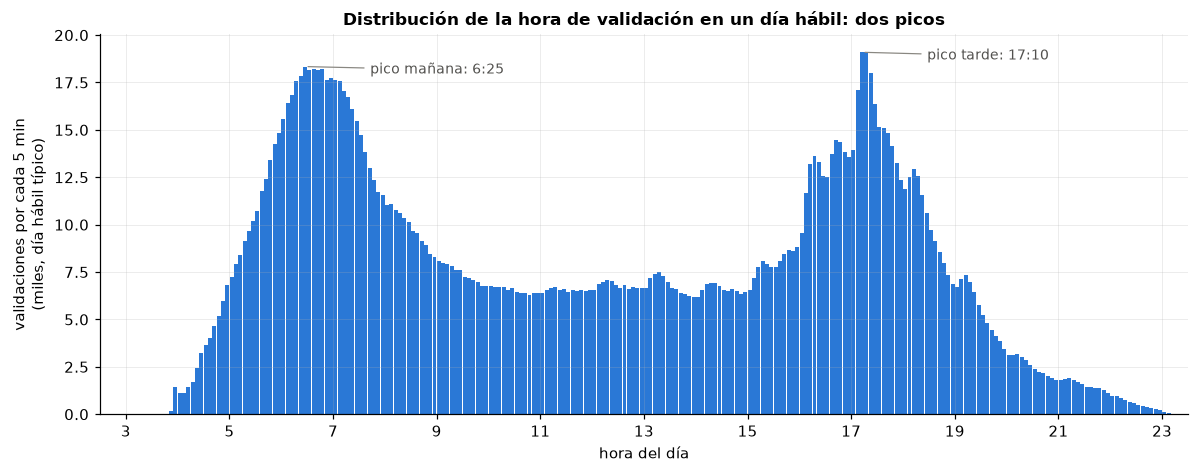

In [7]:
# QUÉ HACE: cuenta las validaciones de los días hábiles minuto a minuto y dibuja su distribución durante el día.
# CÓMO: Dask lee solo la columna de fecha-hora, saca el minuto del día (0 a 1439), filtra los 14 hábiles completos y cuenta por minuto; se divide entre 14 para tener un día hábil típico y se agrupa en barras de 5 minutos.
# QUÉ MIRAR: dos "montañas" (mañana y tarde); cada una sube hasta un máximo y baja, parecida a una campana pero con la cima más plana (meseta en la mañana).
habiles = sorted(calendario[(calendario['tipo_dia'] == 'hábil') & calendario['completo']].index.strftime('%Y-%m-%d'))
print(f"{len(habiles)} días hábiles: {habiles[0]} a {habiles[-1]}")

t0 = time.perf_counter()
ft = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion'])['Fecha_Transaccion']
minuto = ft.str[11:13].astype('int64') * 60 + ft.str[14:16].astype('int64')
por_minuto = (minuto[ft.str[:10].isin(habiles)].to_frame('minuto').groupby('minuto').size()
              .compute().reindex(range(1440), fill_value=0))
print(f"Conteo por minuto en {time.perf_counter() - t0:.0f} s | validaciones en hábiles: {por_minuto.sum():,}")

tipico = por_minuto / len(habiles)                         # un día hábil típico
barras = tipico.groupby(tipico.index // 5).sum()           # barras de 5 minutos
centros = barras.index * 5 / 60 + 2.5 / 60                 # hora (decimal) al centro de cada barra
pico_am = barras[(barras.index * 5 >= 4 * 60) & (barras.index * 5 < 11 * 60)].idxmax()
pico_pm = barras[(barras.index * 5 >= 14 * 60) & (barras.index * 5 < 20 * 60)].idxmax()

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(centros, barras / 1e3, width=5 / 60 * 0.92, color=COL['hábil'])
for p, txt in [(pico_am, 'mañana'), (pico_pm, 'tarde')]:
    h = p * 5 / 60
    ax.annotate(f"pico {txt}: {int(h)}:{int(round((h % 1) * 60)):02d}", xy=(h + 2.5 / 60, barras[p] / 1e3),
                xytext=(h + 1.3, barras[p] / 1e3 * 0.98), fontsize=9, color='#52514e',
                arrowprops=dict(arrowstyle='-', color='#898781', lw=0.8))
ax.set_xlim(2.5, 23.5); ax.set_xticks(range(3, 24, 2)); ax.set_xlabel('hora del día')
ax.set_ylabel('validaciones por cada 5 min\n(miles, día hábil típico)')
ax.set_title('Distribución de la hora de validación en un día hábil: dos picos')
plt.tight_layout(); plt.savefig(FIGS / '03_distribucion_minuto_habil.png', bbox_inches='tight'); plt.show()

In [8]:
# QUÉ HACE: mide qué tan "campana" es cada pico: promedio, mediana, desviación, asimetría y curtosis de la hora de validación.
# CÓMO: con los conteos por minuto como pesos se calculan los momentos de cada ventana (mañana 4:00-10:00 y tarde 15:00-20:00); una normal perfecta tiene asimetría 0 y curtosis en exceso 0.
# QUÉ MIRAR: asimetría cerca de 0 = simétrica; curtosis negativa = cima más plana que una normal. Promedio ≈ mediana indica que la campana es casi simétrica.
def momentos(conteos, ini, fin):
    m = np.arange(ini, fin); w = conteos.loc[ini:fin - 1].values.astype(float)
    mu = np.average(m, weights=w); sd = np.sqrt(np.average((m - mu) ** 2, weights=w))
    asim = np.average(((m - mu) / sd) ** 3, weights=w); curt = np.average(((m - mu) / sd) ** 4, weights=w) - 3
    mediana = m[np.searchsorted(np.cumsum(w) / w.sum(), 0.5)]
    hhmm = lambda x: f"{int(x // 60)}:{int(round(x % 60)):02d}"
    return {'validaciones por día': w.sum() / len(habiles), 'promedio (hora)': hhmm(mu), 'mediana (hora)': hhmm(mediana),
            'desv. estándar (min)': sd, 'asimetría': asim, 'curtosis (exceso)': curt}

forma = pd.DataFrame({'mañana 4:00-10:00': momentos(por_minuto, 240, 600),
                      'tarde 15:00-20:00': momentos(por_minuto, 900, 1200),
                      'día completo': momentos(por_minuto, 0, 1440)}).T
forma

,validaciones por día,promedio (hora),mediana (hora),desv. estándar (min),asimetría,curtosis (exceso)
mañana 4:00-10:00,766765.285714,7:06,7:00,82.205555,0.171323,-0.716735
tarde 15:00-20:00,628438.642857,17:20,17:18,72.326625,0.112067,-0.737822
día completo,1852255.285714,12:09,12:00,292.863519,0.097751,-1.389434


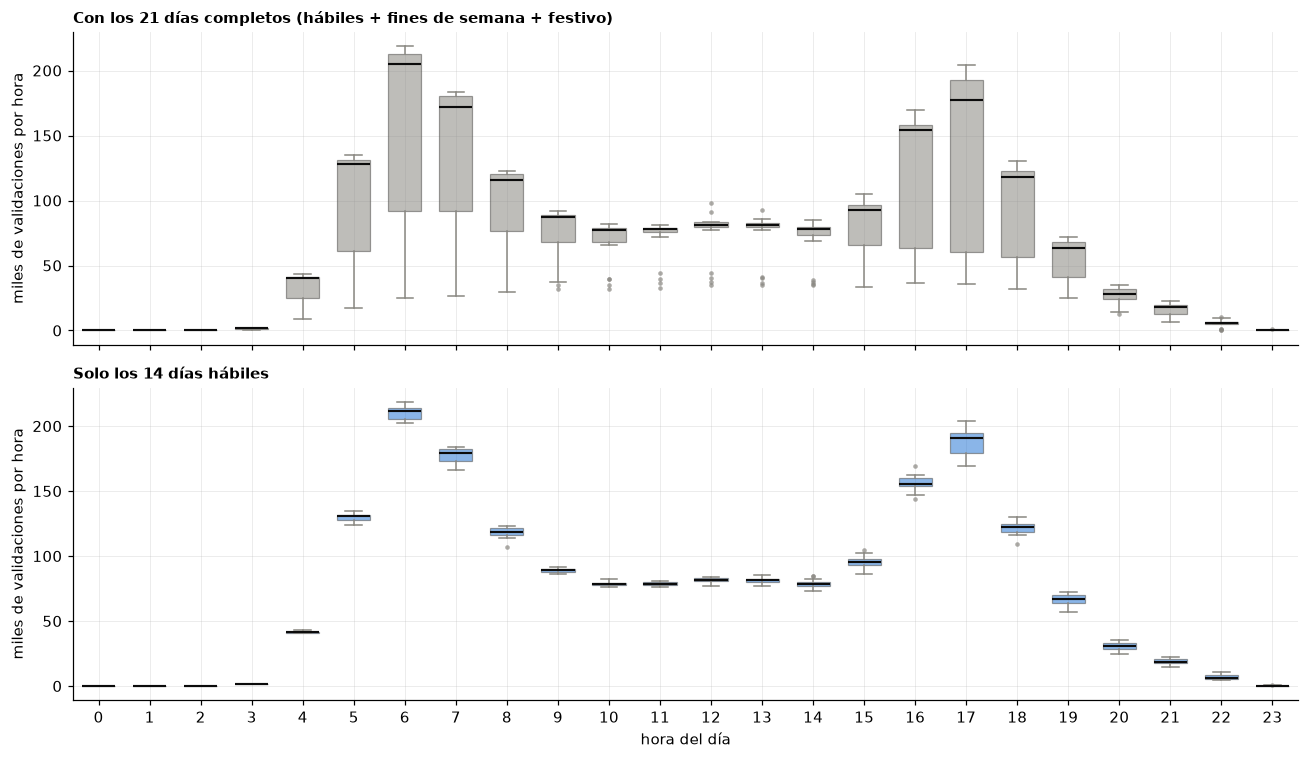

Variación relativa entre días (desviación / promedio) en horas de servicio fuerte:


,todos los días (%),solo hábiles (%)
hora,,
5,47.0,2.3
6,48.7,2.5
7,45.4,3.1
12,24.4,2.2
17,47.9,5.3
18,39.4,4.4


In [9]:
# QUÉ HACE: compara boxplots de las validaciones por hora (total del sistema) usando los 21 días completos vs. solo los 14 hábiles.
# CÓMO: para cada hora hay un valor por día (suma de todas las estaciones); la caja es el rango intercuartil, la línea la mediana y los puntos los días atípicos.
# QUÉ MIRAR: con todos los días las cajas son anchas y tienen puntos sueltos (los fines de semana "caen" lejos); solo con hábiles las cajas son angostas, es decir, hay poca variación entre días comparables.
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True)
estilo = dict(patch_artist=True, widths=0.65, flierprops=dict(marker='o', ms=3, mfc='#898781', mec='none', alpha=0.7),
              medianprops=dict(color='#0b0b0b', lw=1.4), whiskerprops=dict(color='#898781'), capprops=dict(color='#898781'))
es_habil = (tipo_por_dia == 'hábil').values
for ax, dias, titulo, color in [(axes[0], dh, f'Con los {len(dh)} días completos (hábiles + fines de semana + festivo)', '#898781'),
                                (axes[1], dh[es_habil], f'Solo los {es_habil.sum()} días hábiles', COL['hábil'])]:
    bp = ax.boxplot([dias[h] / 1e3 for h in range(24)], positions=range(24), **estilo)
    for caja in bp['boxes']:
        caja.set(facecolor=color, alpha=0.55, edgecolor='#52514e', lw=0.8)
    ax.set_title(titulo, loc='left', fontsize=10); ax.set_ylabel('miles de validaciones por hora')
axes[1].set_xlabel('hora del día'); axes[1].set_xticks(range(24))
plt.tight_layout(); plt.savefig(FIGS / '03_boxplot_hora_con_sin_fin_de_semana.png', bbox_inches='tight'); plt.show()

cv = pd.DataFrame({'todos los días (%)': dh.std() / dh.mean() * 100, 'solo hábiles (%)': dh[es_habil].std() / dh[es_habil].mean() * 100})
print('Variación relativa entre días (desviación / promedio) en horas de servicio fuerte:')
cv.loc[[5, 6, 7, 12, 17, 18]].rename_axis('hora').round(1)

### Lectura de la sección 3

**Distribución de la hora de validación (hábiles)**
- El día completo es **bimodal** (dos montañas): picos a las **6:25** y **17:10**, con un valle de ~6.500 validaciones por 5 min entre las 10 y las 15. En el valle la demanda es ~1/3 de la de los picos.
- **Cada pico es casi una campana**: promedio y mediana están a ~5 min (mañana 7:06 vs. 7:00; tarde 17:20 vs. 17:18) y la asimetría es pequeña (0,17 y 0,11). Pero la **cima es más plana que una normal** (curtosis en exceso ≈ −0,7 en ambos): en la mañana hay una meseta entre las 6:25 y las 6:50, y en la tarde la forma es más "dentada" (salto a las 16:00 y pico a las 17:10).
- Ojo: las ventanas incluyen la cola del valle, así que son campanas aproximadas, no normales perfectas. El día completo (curtosis −1,4) **no** es una campana: es la suma de dos.
- **¿Importa que sea normal?** Para *describir* y para el modelo, no: la variable objetivo es un **conteo** por estación y hora, y la hora entrará como variable explicativa. Importa para **inferir**: justo aquí entra el Teorema del Límite Central (anexo), que explica por qué los *promedios* de la hora de validación sí se comportan como una normal aunque los datos individuales no lo sean.

**Boxplots por hora, con y sin fines de semana**
- Con los 21 días las cajas de las horas pico son enormes (de ~60 a ~210 mil validaciones a las 6 a. m.) porque mezclan un hábil con un domingo: la **variación entre días es 45–49 %** del promedio.
- Con solo los 14 hábiles la caja casi desaparece: **2–5 %** de variación entre días en las mismas horas. Es decir, un día hábil es muy predecible para la misma hora.
- Por eso se quitan los fines de semana y el festivo: no son "ruido" sino **otro régimen** (otra curva y otro nivel), y mezclarlos hace parecer impredecible algo que no lo es. Los pocos puntos sueltos que quedan en hábiles son leves (p. ej. 16 h y 18 h).

**Consecuencia para el resto del EDA:** a nivel de sistema la demanda hábil es muy estable por hora; la pregunta interesante es **dónde** (qué estaciones) se concentra, que es la sección 4.

## 4. ¿Dónde se concentra la demanda? Estaciones, formas horarias y accesos

A nivel de sistema un día hábil es muy estable (sección 3). Ahora se baja a la **estación**, siempre con los 14 días hábiles:

1. **Concentración:** ¿cuántas estaciones reúnen la mayor parte de las validaciones? (tabla y curva de Lorenz).
2. **La variable objetivo, descrita:** cómo se distribuye `validaciones` por estación, fecha y hora (promedio, varianza, ceros).
3. **Formas horarias:** ¿todas las estaciones tienen los dos picos? ¿Hay estaciones "de mañana" y estaciones "de tarde"?
4. **Accesos:** una estación tiene varias entradas (peatonales y plataformas de alimentación por donde llegan los buses zonales). ¿Importan para saber dónde poner personal?

Con más de 100 estaciones, las gráficas muestran **todas** las estaciones (heatmaps, dispersiones) y los rankings solo las 15 primeras más "resto".

In [10]:
# QUÉ HACE: arma la tabla de estaciones (nombre, troncal, tipo) y el "cubo" estación x fecha x hora de los días hábiles, con ceros donde no hubo validaciones.
# CÓMO: el nombre sale de las validaciones (el más frecuente por código); troncal, tipo y número de accesos, del archivo oficial de estaciones; el cubo completa con 0 las horas sin validaciones.
# QUÉ MIRAR: 154 estaciones, 14 días, 24 horas = 51,744 filas del cubo; la suma debe dar 25,931,574 (las validaciones de los días hábiles).
nom = val.groupby('Estacion_Parada').size().compute().rename('n').reset_index()
nom['cod_estacion'] = nom['Estacion_Parada'].str[1:6]; nom['nombre'] = nom['Estacion_Parada'].str[8:]
nom = nom.sort_values('n', ascending=False).drop_duplicates('cod_estacion').set_index('cod_estacion')['nombre']

oficial = pd.read_csv('../data/raw/estaciones/estaciones_troncales.csv', dtype=str, encoding='utf-8-sig').set_index('numero_estacion')
est = pd.DataFrame({'nombre': nom})
est['troncal'] = oficial['troncal_estacion'].reindex(est.index)
est['tipo_estacion'] = oficial['tipo_estacion'].reindex(est.index)
est['vagones'] = pd.to_numeric(oficial['numero_vagones_estacion'].reindex(est.index))
est['accesos_oficiales'] = pd.to_numeric(oficial['numero_accesos_estacion'].reindex(est.index))

ph = panel[(panel['tipo_dia'] == 'hábil') & panel['completo']]
idx = pd.MultiIndex.from_product([sorted(panel['cod_estacion'].unique()), habiles, range(24)], names=['cod_estacion', 'fecha', 'hora'])
cubo = ph.set_index(['cod_estacion', 'fecha', 'hora'])['validaciones'].reindex(idx, fill_value=0)
assert cubo.sum() == por_minuto.sum(), 'el cubo no cuadra con el conteo por minuto'
print(f"Cubo: {len(cubo):,} filas | suma = {cubo.sum():,} | estaciones sin troncal en el archivo oficial: {est['troncal'].isna().sum()}")

por_est_hora = cubo.groupby(['cod_estacion', 'hora']).mean().unstack()          # validaciones por hora, promedio de un día hábil
est['val_dia'] = por_est_hora.sum(axis=1)
est['hora_pico'] = por_est_hora.idxmax(axis=1)
est['val_hora_pico'] = por_est_hora.max(axis=1)
est = est.sort_values('val_dia', ascending=False)
est['% del sistema'] = est['val_dia'] / est['val_dia'].sum() * 100
est['% acumulado'] = est['% del sistema'].cumsum()
est.head(15).round(1)

Cubo: 51,744 filas | suma = 25,931,574 | estaciones sin troncal en el archivo oficial: 18


,nombre,troncal,tipo_estacion,vagones,accesos_oficiales,val_dia,hora_pico,val_hora_pico,% del sistema,% acumulado
cod_estacion,,,,,,,,,,
05000,Portal Américas,Americas,1,1.0,0.0,71392.6,6,14411.6,3.9,3.9
02000,Portal Norte - Unicervantes,Autonorte,1,1.0,0.0,70314.5,7,9369.2,3.8,7.7
03000,Portal Suba,Suba,1,1.0,0.0,56195.7,6,11407.1,3.0,10.7
07000,Portal Sur JFK Coop. Financiera,NQS,1,1.0,0.0,56063.7,6,11663.7,3.0,13.7
04000,Cabecera Calle 80,Calle 80,1,1.0,0.0,53151.8,7,8619.9,2.9,16.6
09000,Cabecera Usme,Caracas,1,1.0,0.0,51424.4,6,10449.1,2.8,19.4
06000,Portal El Dorado - C.C. NUESTRO BOGOTA,Calle 26,1,1.0,0.0,49292.4,7,6167.1,2.7,22.0
10000,Portal 20 de Julio,Cr 7-10,1,1.0,0.0,41969.4,6,8207.3,2.3,24.3
02300,Calle 100 - Marketmedios,Autonorte,4,3.0,2.0,41609.2,17,7646.9,2.2,26.5


Para llegar al 50 % de las validaciones hacen falta 27 estaciones y para el 80 %, 75 (de 154).
Índice de Gini = 0.48


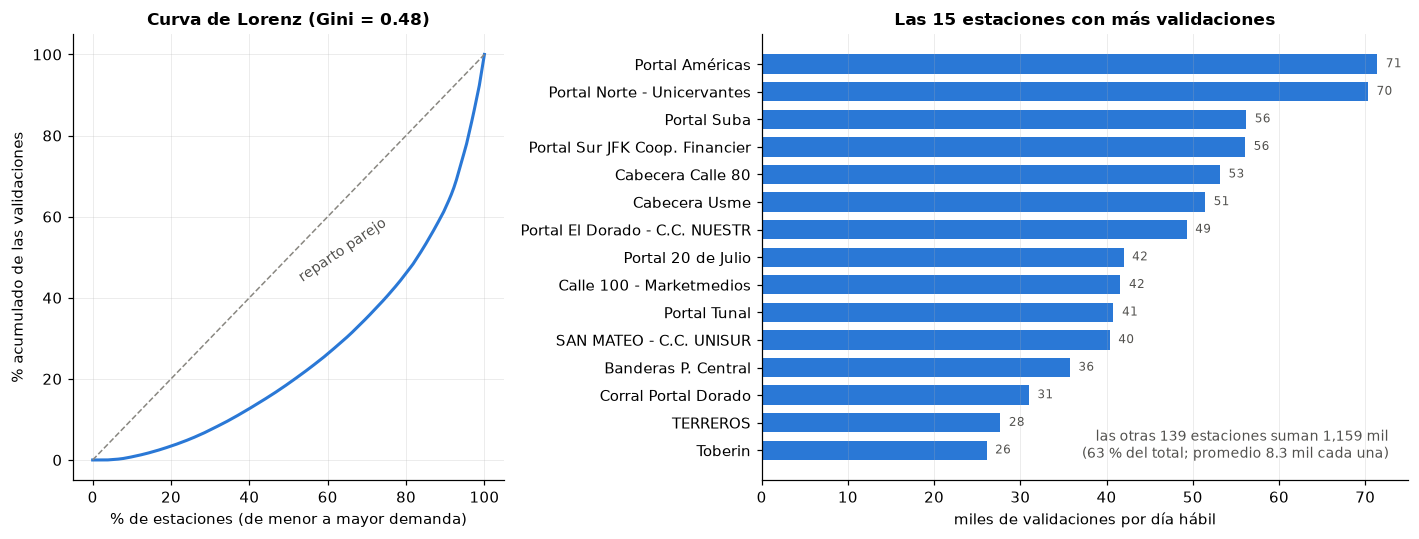

,estaciones,% de las estaciones,% de las validaciones
0,5,3.2,16.6
1,10,6.5,28.7
2,15,9.7,37.4
3,20,13.0,43.4
4,30,19.5,53.3
5,50,32.5,67.3


In [11]:
# QUÉ HACE: mide qué tan concentradas están las validaciones en pocas estaciones: tabla de concentración, curva de Lorenz y ranking de las 15 primeras (el "resto" se anota aparte).
# CÓMO: se ordenan las estaciones de menor a mayor demanda y se acumula su participación; la diagonal sería un reparto perfectamente parejo; el índice de Gini resume la desigualdad (0 = parejo, 1 = todo en una).
# QUÉ MIRAR: cuántas estaciones hacen falta para llegar al 50 % y al 80 % de las validaciones, y qué tan lejos de la diagonal queda la curva.
n_est = len(est)
conc = pd.DataFrame({'estaciones': [5, 10, 15, 20, 30, 50]})
conc['% de las estaciones'] = conc['estaciones'] / n_est * 100
conc['% de las validaciones'] = [est['% del sistema'].head(k).sum() for k in conc['estaciones']]
print(f"Para llegar al 50 % de las validaciones hacen falta {int((est['% acumulado'] < 50).sum() + 1)} estaciones y para el 80 %, {int((est['% acumulado'] < 80).sum() + 1)} (de {n_est}).")

asc = est['val_dia'].sort_values().values
lorenz = np.insert(np.cumsum(asc) / asc.sum(), 0, 0)
gini = 1 - 2 * np.trapezoid(lorenz, dx=1 / n_est)
print(f"Índice de Gini = {gini:.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.5]})
a1.plot(np.linspace(0, 100, n_est + 1), lorenz * 100, color=COL['hábil'], lw=2)
a1.plot([0, 100], [0, 100], color='#898781', lw=1, ls='--')
a1.text(52, 44, 'reparto parejo', color='#52514e', fontsize=9, rotation=34)
a1.set_xlabel('% de estaciones (de menor a mayor demanda)'); a1.set_ylabel('% acumulado de las validaciones')
a1.set_title(f'Curva de Lorenz (Gini = {gini:.2f})')
top = est.head(15).iloc[::-1]
a2.barh([n[:30] for n in top['nombre']], top['val_dia'] / 1e3, color=COL['hábil'], height=0.7)
for p in a2.patches:
    a2.text(p.get_width() + 1, p.get_y() + p.get_height() / 2, f"{p.get_width():.0f}", va='center', fontsize=8, color='#52514e')
resto = est['val_dia'].iloc[15:]
a2.text(0.97, 0.04, f"las otras {len(resto)} estaciones suman {resto.sum() / 1e3:,.0f} mil\n({resto.sum() / est['val_dia'].sum() * 100:.0f} % del total; promedio {resto.mean() / 1e3:.1f} mil cada una)",
        transform=a2.transAxes, ha='right', va='bottom', fontsize=9, color='#52514e')
a2.set_xlabel('miles de validaciones por día hábil'); a2.set_title('Las 15 estaciones con más validaciones')
a2.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(FIGS / '03_concentracion_estaciones.png', bbox_inches='tight'); plt.show()
conc.round(1)

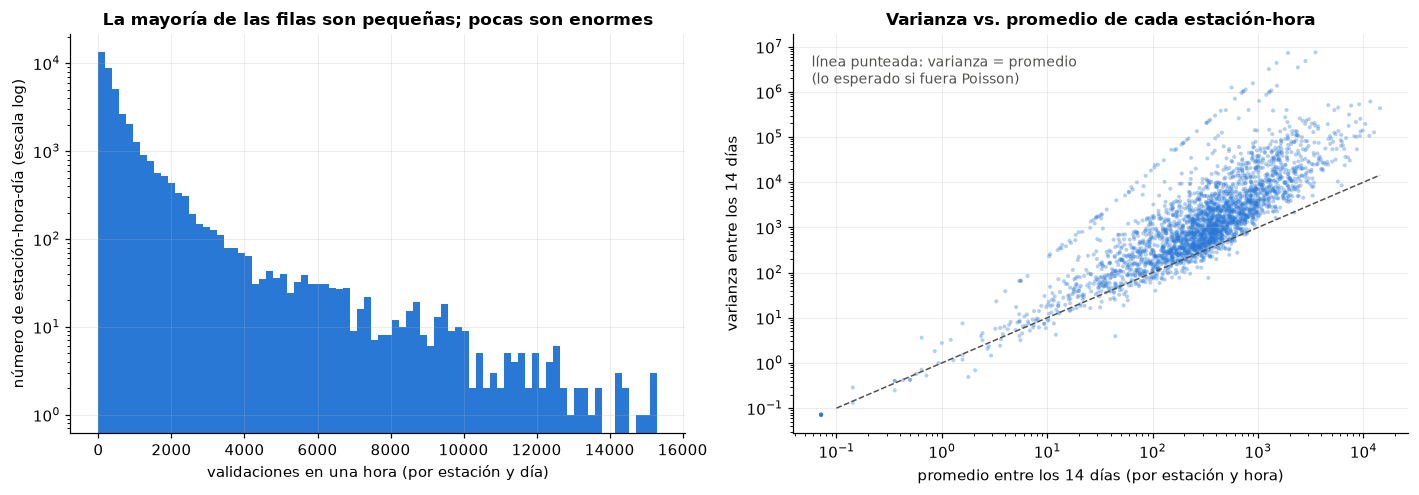

Varianza / promedio entre días (mediana de 2,708 estación-hora): 3.4 | con promedio > 1,000 validaciones: 8.7


,validaciones
filas (estación-fecha-hora),38808.00
promedio,652.59
mediana,317.00
desviación estándar,1131.48
varianza,1280254.02
varianza / promedio,1961.82
percentil 95,2357.30
percentil 99,6080.86
máximo,15308.00
% de filas con 0 validaciones,4.79


In [12]:
# QUÉ HACE: describe la variable objetivo (validaciones por estación, fecha y hora) en horas de servicio (5:00 a 22:59) y compara su promedio con su varianza.
# CÓMO: tabla de estadísticas y dos gráficas: el histograma de la variable (eje vertical logarítmico) y, para cada estación-hora, el promedio contra la varianza entre los 14 días (ambos ejes logarítmicos).
# QUÉ MIRAR: media muy por encima de la mediana (cola larga a la derecha); los puntos por encima de la línea punteada (varianza > promedio) y más arriba mientras más grande es la demanda; ceros solo en estaciones pequeñas.
servicio = cubo[cubo.index.get_level_values('hora').isin(range(5, 23))]
y = servicio.astype(float)
desc = pd.Series({'filas (estación-fecha-hora)': len(y), 'promedio': y.mean(), 'mediana': y.median(), 'desviación estándar': y.std(),
                  'varianza': y.var(), 'varianza / promedio': y.var() / y.mean(), 'percentil 95': y.quantile(0.95),
                  'percentil 99': y.quantile(0.99), 'máximo': y.max(), '% de filas con 0 validaciones': (y == 0).mean() * 100,
                  'asimetría': y.skew()}, name='validaciones')

mv = servicio.groupby(['cod_estacion', 'hora']).agg(['mean', 'var'])
mv = mv[mv['mean'] > 0]
mv['razon'] = mv['var'] / mv['mean']

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
a1.hist(y, bins=80, color=COL['hábil'])
a1.set_yscale('log'); a1.set_xlabel('validaciones en una hora (por estación y día)'); a1.set_ylabel('número de estación-hora-día (escala log)')
a1.set_title('La mayoría de las filas son pequeñas; pocas son enormes')
a2.scatter(mv['mean'], mv['var'], s=7, color=COL['hábil'], alpha=0.35, edgecolors='none')
lim = [max(mv['mean'].min(), 1e-1), mv['mean'].max()]
a2.plot(lim, lim, color='#52514e', lw=1, ls='--'); a2.text(0.03, 0.95, 'línea punteada: varianza = promedio\n(lo esperado si fuera Poisson)', transform=a2.transAxes, fontsize=9, color='#52514e', va='top')
a2.set_xscale('log'); a2.set_yscale('log')
a2.set_xlabel('promedio entre los 14 días (por estación y hora)'); a2.set_ylabel('varianza entre los 14 días')
a2.set_title('Varianza vs. promedio de cada estación-hora')
plt.tight_layout(); plt.savefig(FIGS / '03_variable_objetivo.png', bbox_inches='tight'); plt.show()

print(f"Varianza / promedio entre días (mediana de {len(mv):,} estación-hora): {mv['razon'].median():.1f} | con promedio > 1,000 validaciones: {mv.loc[mv['mean'] > 1000, 'razon'].median():.1f}")
desc.round(2).to_frame()

Estaciones casi sin uso (< 100 validaciones por día), excluidas de las formas: ['02305', '08100', '50006', '50004', '05001']


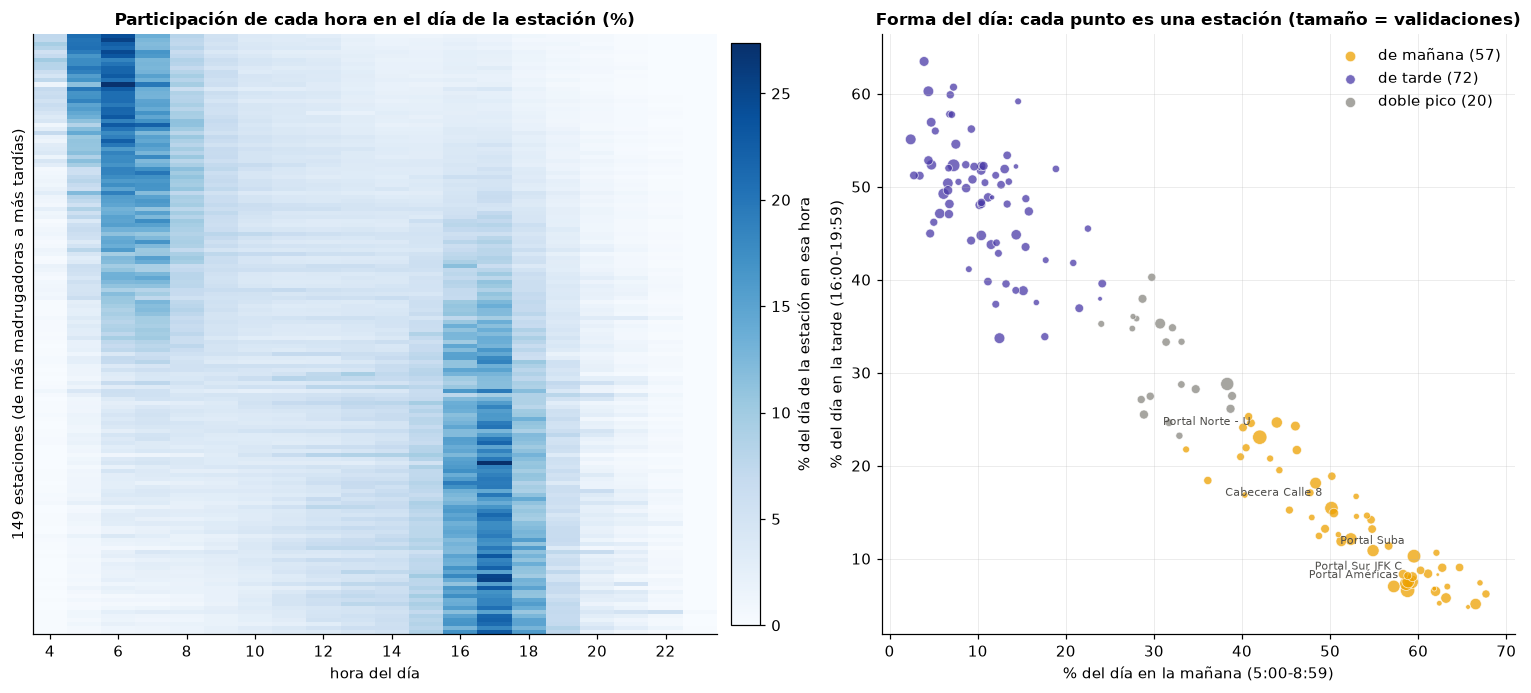

,estaciones,val_por_dia,ejemplos,% de las validaciones
forma,,,,
de mañana,57,930424.6,"Portal Américas, Portal Norte - Unicerv, Porta...",50.2
de tarde,72,731510.3,"Calle 100 - Marketmedi, Temporal Flores, Tempo...",39.5
doble pico,20,190289.2,"Portal El Dorado - C.C, Alcalá – Colegio S. To...",10.3


In [13]:
# QUÉ HACE: compara la forma del día de todas las estaciones activas: heatmap de la participación de cada hora en el día de la estación y clasificación en "de mañana", "de tarde" o "doble pico".
# CÓMO: para cada estación se divide la demanda de cada hora entre su total del día (así se compara la forma, no el tamaño); mañana = 5:00-8:59, tarde = 16:00-19:59; si la mañana pesa más de 60 % de (mañana + tarde) es "de mañana", si pesa menos de 40 % es "de tarde". Las estaciones con menos de 100 validaciones por día (casi sin uso) se dejan fuera.
# QUÉ MIRAR: la franja oscura se mueve de la mañana a la tarde al bajar por el heatmap; en la dispersión las estaciones grandes (portales) quedan en la esquina de "mañana"; cuánta demanda reúne cada grupo.
est['activa'] = est['val_dia'] >= 100
print(f"Estaciones casi sin uso (< 100 validaciones por día), excluidas de las formas: {list(est[~est['activa']].index)}")
act = est.index[est['activa']]

forma_est = por_est_hora.loc[act].div(por_est_hora.loc[act].sum(axis=1), axis=0)     # participación de cada hora en el día de la estación
am = forma_est.loc[:, 5:8].sum(axis=1); pm = forma_est.loc[:, 16:19].sum(axis=1)
est['pct_manana'] = (am * 100).reindex(est.index); est['pct_tarde'] = (pm * 100).reindex(est.index)
razon = (am / (am + pm)).reindex(est.index)
est['forma'] = np.select([~est['activa'], razon > 0.6, razon < 0.4], ['sin uso', 'de mañana', 'de tarde'], default='doble pico')
CF = {'de mañana': '#eda100', 'de tarde': '#4a3aa7', 'doble pico': '#898781'}

hora_media = por_est_hora.loc[act].mul(np.arange(24)).sum(axis=1) / por_est_hora.loc[act].sum(axis=1)
orden = hora_media.sort_values().index                                              # de la hora media de entrada más temprana a la más tardía
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.4), gridspec_kw={'width_ratios': [1.15, 1]})
im = a1.imshow(forma_est.loc[orden, 4:23].values * 100, aspect='auto', cmap='Blues', interpolation='nearest')
a1.set_xticks(range(0, 20, 2)); a1.set_xticklabels(range(4, 24, 2)); a1.set_yticks([]); a1.grid(False)
a1.set_xlabel('hora del día'); a1.set_ylabel(f'{len(act)} estaciones (de más madrugadoras a más tardías)')
a1.set_title('Participación de cada hora en el día de la estación (%)')
cb = fig.colorbar(im, ax=a1, fraction=0.04, pad=0.02); cb.set_label('% del día de la estación en esa hora')
for f, c in CF.items():
    s = est[est['forma'] == f]
    a2.scatter(s['pct_manana'], s['pct_tarde'], s=np.sqrt(s['val_dia']) / 3, color=c, alpha=0.75, edgecolors='white', linewidths=0.5, label=f"{f} ({len(s)})")
for cod, r in est.head(5).iterrows():
    a2.annotate(r['nombre'][:16], (r['pct_manana'], r['pct_tarde']), xytext=(-6, 8), textcoords='offset points', fontsize=7.5, color='#52514e', ha='right')
a2.set_xlabel('% del día en la mañana (5:00-8:59)'); a2.set_ylabel('% del día en la tarde (16:00-19:59)')
a2.set_title('Forma del día: cada punto es una estación (tamaño = validaciones)')
a2.legend(loc='upper right')
plt.tight_layout(); plt.savefig(FIGS / '03_formas_horarias_estaciones.png', bbox_inches='tight'); plt.show()

formas = est[est['activa']].groupby('forma').agg(estaciones=('nombre', 'size'), val_por_dia=('val_dia', 'sum'),
                                                 ejemplos=('nombre', lambda s: ', '.join(n[:22] for n in s.head(3))))
formas['% de las validaciones'] = formas['val_por_dia'] / formas['val_por_dia'].sum() * 100
formas.round(1)

### 4.4 Los accesos de la estación

Cada validación dice por **qué acceso** entró la persona. Algunos accesos son **plataformas de alimentación** (por ahí llegan los buses zonales que descargan pasajeros de golpe) y otros son accesos peatonales. Para el apoyo logístico importa por qué punto entra la gente: dos estaciones con la misma demanda pueden necesitar distinto personal si una reparte la entrada en cuatro puertas y la otra la concentra en una.

In [14]:
# QUÉ HACE: cuenta las validaciones de los días hábiles por estación, acceso y hora, y clasifica cada acceso en "alimentación" (plataforma por donde llegan buses zonales) o "peatonal / otro".
# CÓMO: Dask agrupa por (estación, acceso, hora) en los 14 hábiles; un acceso es de alimentación si su nombre contiene ALIM, PLAT o DESAL (hay ~420 nombres distintos, escritos de muchas formas).
# QUÉ MIRAR: cuántas validaciones entran por alimentación vs. por accesos peatonales; ejemplos de nombres en cada clase para revisar que la regla sea razonable.
t0 = time.perf_counter()
vb = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion', 'Estacion_Parada', 'Acceso_Estacion'])
vb = vb[vb['Fecha_Transaccion'].str[:10].isin(habiles)]
acc = (vb.assign(cod_estacion=vb['Estacion_Parada'].str[1:6], hora=vb['Fecha_Transaccion'].str[11:13].astype('int64'))
         .groupby(['cod_estacion', 'Acceso_Estacion', 'hora']).size().compute().rename('validaciones').reset_index())
acc['validaciones'] = acc['validaciones'] / len(habiles)                        # promedio de un día hábil
assert abs(acc['validaciones'].sum() * len(habiles) - por_minuto.sum()) < 1
print(f"Conteo por acceso en {time.perf_counter() - t0:.0f} s | {acc['Acceso_Estacion'].nunique()} nombres de acceso distintos")

acc['clase'] = np.where(acc['Acceso_Estacion'].str.upper().str.contains('ALIM|PLAT|DESAL'), 'alimentación', 'peatonal / otro')
resumen_acc = acc.groupby('clase').agg(nombres=('Acceso_Estacion', 'nunique'), val_por_dia=('validaciones', 'sum'))
resumen_acc['% de las validaciones'] = resumen_acc['val_por_dia'] / resumen_acc['val_por_dia'].sum() * 100
resumen_acc['ejemplos de nombres'] = [' | '.join(acc[acc['clase'] == c].groupby('Acceso_Estacion')['validaciones'].sum().nlargest(3).index.str[:45]) for c in resumen_acc.index]
pd.set_option('display.max_colwidth', 160)
resumen_acc.round(1)

Conteo por acceso en 13 s | 432 nombres de acceso distintos


,nombres,val_por_dia,% de las validaciones,ejemplos de nombres
clase,,,,
alimentación,115,397107.2,21.4,(01) ALIMENTACIÓN JUAN REY/ALTAMIRA/TIHUAQUE/ | (07) ALIMENTACIÓN PLATAFORMA 1 | (02) PLATAFORMA 2 ALIMENTACION CONSORCIO EXPR
peatonal / otro,317,1455148.1,78.6,(01) Acceso Norte | (02) Acceso Sur | (01) Acceso Peatonal Oriental


In [15]:
# QUÉ HACE: para cada estación calcula qué parte de su demanda entra por alimentación, cuántos accesos usa de verdad y cómo se reparte la hora pico entre ellos.
# CÓMO: % por alimentación en el día; en la hora pico de la estación: validaciones del acceso principal (% y número), accesos que aportan >= 10 % y validaciones por acceso activo.
# QUÉ MIRAR: estaciones con mucho % de alimentación (llegan en oleadas de buses zonales) y estaciones cuya hora pico se concentra en un solo acceso (más carga por entrada = más fila en un punto).
alim = acc[acc['clase'] == 'alimentación'].groupby('cod_estacion')['validaciones'].sum()
est['pct_alimentacion'] = (alim.reindex(est.index).fillna(0) / est['val_dia'] * 100)
est['accesos_con_uso'] = acc.groupby('cod_estacion')['Acceso_Estacion'].nunique().reindex(est.index)

pico = acc.merge(est[['hora_pico']].reset_index(), on='cod_estacion')
pico = pico[pico['hora'] == pico['hora_pico']]
tot_pico = pico.groupby('cod_estacion')['validaciones'].sum()
pico['peso'] = pico['validaciones'] / pico['cod_estacion'].map(tot_pico)
est['pct_acceso_principal_pico'] = pico.groupby('cod_estacion')['peso'].max().reindex(est.index) * 100
est['accesos_activos_pico'] = pico[pico['peso'] >= 0.10].groupby('cod_estacion').size().reindex(est.index)
est['val_por_acceso_pico'] = est['val_hora_pico'] / est['accesos_activos_pico']

cols = ['nombre', 'tipo_estacion', 'val_dia', 'hora_pico', 'val_hora_pico', 'pct_alimentacion', 'accesos_activos_pico', 'pct_acceso_principal_pico', 'val_por_acceso_pico']
print('Las 15 estaciones con más demanda: accesos en su hora pico')
est[cols].head(15).round(1)

Las 15 estaciones con más demanda: accesos en su hora pico


,nombre,tipo_estacion,val_dia,hora_pico,val_hora_pico,pct_alimentacion,accesos_activos_pico,pct_acceso_principal_pico,val_por_acceso_pico
cod_estacion,,,,,,,,,
05000,Portal Américas,1,71392.6,6,14411.6,65.0,3.0,41.2,4803.9
02000,Portal Norte - Unicervantes,1,70314.5,7,9369.2,64.3,4.0,31.5,2342.3
03000,Portal Suba,1,56195.7,6,11407.1,74.6,3.0,35.3,3802.4
07000,Portal Sur JFK Coop. Financiera,1,56063.7,6,11663.7,75.7,4.0,25.6,2915.9
04000,Cabecera Calle 80,1,53151.8,7,8619.9,65.0,4.0,32.1,2155.0
09000,Cabecera Usme,1,51424.4,6,10449.1,68.5,3.0,32.8,3483.0
06000,Portal El Dorado - C.C. NUESTRO BOGOTA,1,49292.4,7,6167.1,59.4,3.0,40.2,2055.7
10000,Portal 20 de Julio,1,41969.4,6,8207.3,62.5,3.0,54.8,2735.8
02300,Calle 100 - Marketmedios,4,41609.2,17,7646.9,0.0,2.0,54.9,3823.4


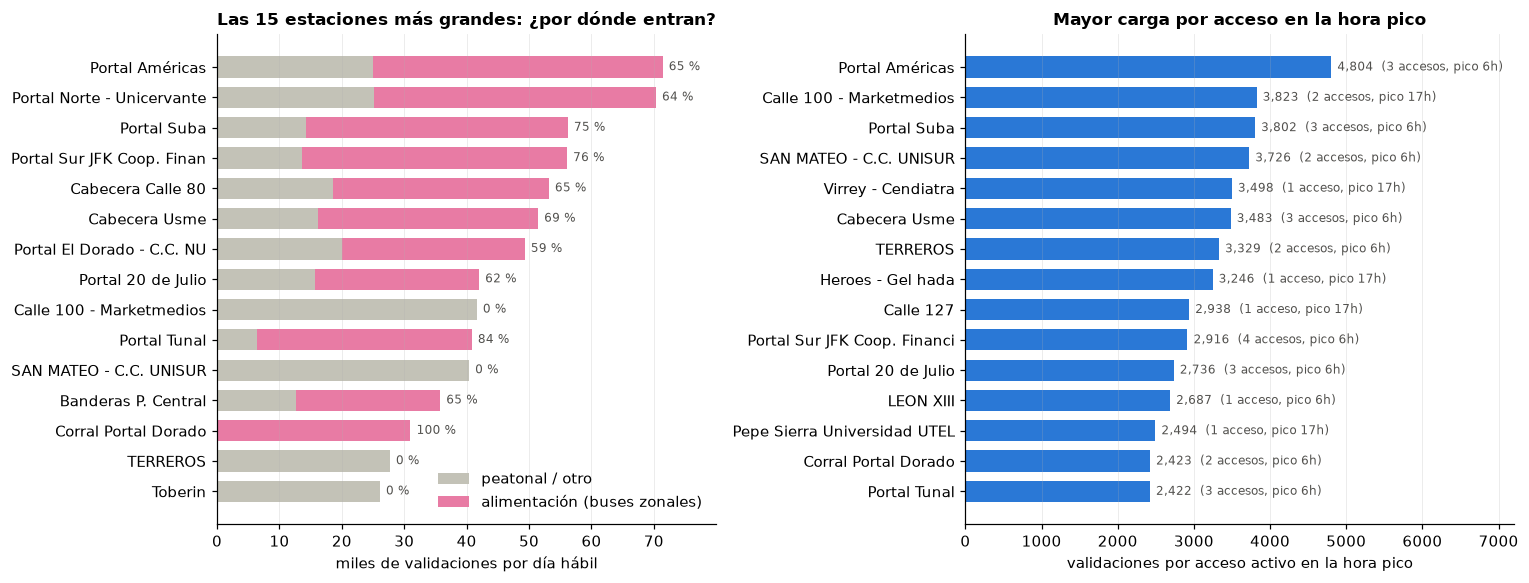

Correlación de Spearman entre el ranking por validaciones en la hora pico y por carga por acceso: 0.87
Estaciones activas con un solo acceso en la hora pico: 78 de 149 | con 3 o más: 18


,estaciones,validaciones por día
pct_alimentacion,,
0-5 %,135,1261629.0
5-60 %,4,82557.0
60-100 %,10,508038.0


In [16]:
# QUÉ HACE: muestra en dos gráficas si los accesos importan: (izq.) de dónde entra la demanda de las 15 estaciones más grandes (alimentación vs. peatonal); (der.) la carga por acceso activo en la hora pico.
# CÓMO: izquierda: barras apiladas con las validaciones por día de cada clase de acceso; derecha: las 15 estaciones activas con más validaciones por acceso activo en su hora pico.
# QUÉ MIRAR: los portales reciben 60-85 % por alimentación (llegan en oleadas de buses zonales), el resto de estaciones casi nada; y si el ranking por "carga por acceso" cambia frente al ranking por validaciones totales (si cambia, el acceso aporta información nueva).
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1, 1.1]})
t15 = est.head(15).iloc[::-1]
v_alim = t15['val_dia'] * t15['pct_alimentacion'] / 100; v_peat = t15['val_dia'] - v_alim
a1.barh([n[:26] for n in t15['nombre']], v_peat / 1e3, color='#c3c2b7', height=0.7, label='peatonal / otro')
a1.barh([n[:26] for n in t15['nombre']], v_alim / 1e3, left=v_peat / 1e3, color='#e87ba4', height=0.7, label='alimentación (buses zonales)')
for i, (pct, tot) in enumerate(zip(t15['pct_alimentacion'], t15['val_dia'])):
    a1.text(tot / 1e3 + 1, i, f"{pct:.0f} %", va='center', fontsize=8, color='#52514e')
a1.set_xlim(0, t15['val_dia'].max() / 1e3 * 1.12)
a1.set_xlabel('miles de validaciones por día hábil'); a1.set_title('Las 15 estaciones más grandes: ¿por dónde entran?')
a1.legend(loc='lower right'); a1.grid(axis='y', visible=False)

carga = est[est['activa']].dropna(subset=['val_por_acceso_pico']).nlargest(15, 'val_por_acceso_pico').iloc[::-1]
a2.barh([n[:28] for n in carga['nombre']], carga['val_por_acceso_pico'], color=COL['hábil'], height=0.7)
for p, (_, r) in zip(a2.patches, carga.iterrows()):
    n_ac = int(r['accesos_activos_pico'])
    a2.text(p.get_width() + 80, p.get_y() + p.get_height() / 2, f"{r['val_por_acceso_pico']:,.0f}  ({n_ac} {'acceso' if n_ac == 1 else 'accesos'}, pico {int(r['hora_pico'])}h)", va='center', fontsize=8, color='#52514e')
a2.set_xlim(0, carga['val_por_acceso_pico'].max() * 1.5)
a2.set_xlabel('validaciones por acceso activo en la hora pico'); a2.set_title('Mayor carga por acceso en la hora pico'); a2.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(FIGS / '03_accesos.png', bbox_inches='tight'); plt.show()

act_est = est[est['activa']]
rank_total = act_est['val_hora_pico'].rank(ascending=False); rank_acceso = act_est['val_por_acceso_pico'].rank(ascending=False)
print(f"Correlación de Spearman entre el ranking por validaciones en la hora pico y por carga por acceso: {rank_total.corr(rank_acceso):.2f}")
print(f"Estaciones activas con un solo acceso en la hora pico: {(act_est['accesos_activos_pico'] == 1).sum()} de {len(act_est)} | con 3 o más: {(act_est['accesos_activos_pico'] >= 3).sum()}")
act_est.groupby(pd.cut(act_est['pct_alimentacion'], [-0.1, 5, 60, 100.1], labels=['0-5 %', '5-60 %', '60-100 %']))['val_dia'].agg(['count', 'sum']).rename(columns={'count': 'estaciones', 'sum': 'validaciones por día'}).round(0)

### Lectura de la sección 4

**Concentración (4.1)**
- La demanda está **repartida de forma moderadamente desigual** (Gini 0,48): 27 de las 154 estaciones (18 %) reúnen la mitad de las validaciones y 75 estaciones, el 80 %. Las 5 más grandes suman 16,6 %; las 15 más grandes, 37,4 %.
- Las más grandes son **portales y cabeceras** (Américas, Norte, Suba, Sur, Calle 80, Usme, El Dorado, 20 de Julio, Tunal) con 41–71 mil validaciones por día hábil, junto con Calle 100, San Mateo, Banderas, Terreros y Toberín. Las otras 139 estaciones promedian 8,3 mil.
- Hay 5 estaciones casi sin uso (< 100 validaciones por día) que se dejan fuera de las formas y de los rankings. Además, 18 estaciones no aparecen con troncal en el archivo oficial (entre ellas el Corral Portal Dorado), así que ese archivo no sirve como única fuente de atributos.

**La variable objetivo (4.2)**
- Es un **conteo muy asimétrico** (asimetría 5,0): promedio 653 vs. mediana 317 validaciones por estación-hora; el percentil 99 es 6.081 y el máximo 15.308. Un 4,8 % de las filas en horas de servicio son ceros (estaciones pequeñas de madrugada o noche).
- **La varianza entre días es mayor que el promedio** en casi todas las estaciones-hora y la brecha crece con el tamaño: la razón varianza/promedio tiene mediana 3,4 y sube a 8,7 en las estaciones-hora con más de 1.000 validaciones. **No es un Poisson puro** (daría 1): hay más variación entre días de la que daría el azar. Esto importa para escoger la métrica y el modelo. (La razón global, 1.962, solo refleja que se mezclan estaciones de tamaños muy distintos; no se interpreta.)

**Formas horarias (4.3)**
- Las estaciones se separan en tres tipos: **57 "de mañana"** (50 % de las validaciones; incluye los portales y cabeceras), **72 "de tarde"** (40 %) y **20 de "doble pico"** (10 %).
- El heatmap lo muestra como una franja que **se mueve de las 6 a. m. a las 5 p. m.**: las estaciones de la periferia (donde empieza el viaje) pesan en la mañana y las demás pesan en la tarde (retorno). *Esto es una hipótesis a confirmar con el mapa y con el viaje de ida y vuelta (secciones 6 y 7).*
- **Consecuencia:** "dónde" y "cuándo" no se pueden separar. Una estación necesita apoyo en *su* punta, no en la punta del sistema.

**Accesos (4.4)**
- El **21,4 %** de las validaciones entra por accesos de alimentación (plataformas de buses zonales), pero está **muy concentrado**: 10 estaciones reciben más del 60 % por ahí (los portales, 59–84 %, y el Corral Portal Dorado, 100 %) y 135 estaciones, menos del 5 %.
- En los portales la entrada es **en oleadas de buses**, no continua; ahí el acceso sí cambia la historia: dos portales con la misma demanda pueden tener cargas distintas por puerta.
- La **carga por acceso** en la hora pico (validaciones por acceso que aporta ≥ 10 %) reordena algo el ranking (Américas 4.804, Calle 100 3.823, Suba 3.802), pero **se parece mucho al ranking por validaciones totales** (Spearman 0,87). Y 78 de 149 estaciones usan un solo acceso en su hora pico.
- Conclusión provisional: los accesos aportan **un matiz importante en los portales** y poco en el resto. Se guardan como **características de la estación** (`pct_alimentacion`, número de accesos activos, % del acceso principal) y no como unidad de análisis (por acceso la tabla sería mucho más grande y con nombres inconsistentes: 432 nombres distintos).

**Decisión para el resto del EDA:** la unidad de análisis sigue siendo **estación × día × hora** (o franja), con atributos fijos de la estación (tipo, % de alimentación, forma del día). Siguen: quiénes entran (perfiles y tarifas), el mapa y el viaje de ida y vuelta.

## 5. ¿Quiénes entran? Perfiles, tarjetas y tarifas por hora

Hasta ahora se contó **cuánta** gente entra. Ahora se mira **quién**, con las columnas que describen la validación (siempre días hábiles):

- `Nombre_Perfil`: tipo de usuario (Adulto, Adulto Mayor, Discapacidad, Apoyo Ciudadano, etc.). El perfil *Anonymous* corresponde a la tarjeta **tullave Básica** (sin datos de la persona); el resto, a **tullave Plus** (personalizada).
- `Tipo_Tarifa` (1, 2 o 3) y `Valor` (lo cobrado: $3.550 o $0). Se explora qué significa cada tarifa cruzándola con el perfil y con el cobro; **no se asume**.
- `Emisor`: quién emitió el medio de pago. Si no es Bogotá Card (tullave), es una **tarjeta bancaria o similar** que se pasa directamente en el torniquete.

La pregunta es si **la mezcla de usuarios cambia con la hora y con el tipo de estación**, porque distintos usuarios pueden necesitar distinta atención (por ejemplo, personas sin tullave o que pagan con tarjeta bancaria).

In [17]:
# QUÉ HACE: cuenta las validaciones de los días hábiles por estación, hora, perfil, tarjeta, tarifa, tipo de emisor y si se cobró $0, y resume cada perfil en una tabla.
# CÓMO: Dask agrupa las 25.9 millones de validaciones en una tabla pequeña (promedio de un día hábil); luego se calculan porcentajes por perfil. Emisor distinto de Bogotá Card = tarjeta bancaria u otro medio.
# QUÉ MIRAR: Anonymous (tullave Básica) nunca tiene tarifa 2 ni 3; las tarifas 2 y 3 siempre cobran $0; qué perfiles pesan más; cuánta gente paga con tarjeta bancaria.
t0 = time.perf_counter()
vp = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion', 'Estacion_Parada', 'Nombre_Perfil', 'Tipo_Tarjeta', 'Tipo_Tarifa', 'Emisor', 'Valor'])
vp = vp[vp['Fecha_Transaccion'].str[:10].isin(habiles)]
vp = vp.assign(cod_estacion=vp['Estacion_Parada'].str[1:6], hora=vp['Fecha_Transaccion'].str[11:13].astype('int64'),
               perfil=vp['Nombre_Perfil'].str[6:], bancaria=~vp['Emisor'].str.contains('Bogota Card'), valor0=(vp['Valor'] == 0))
comp = (vp.groupby(['cod_estacion', 'hora', 'perfil', 'Tipo_Tarjeta', 'Tipo_Tarifa', 'bancaria', 'valor0']).size()
          .compute().rename('validaciones').reset_index())
comp['validaciones'] = comp['validaciones'] / len(habiles)                          # promedio de un día hábil
assert abs(comp['validaciones'].sum() * len(habiles) - por_minuto.sum()) < 1, 'se perdieron validaciones'
print(f"Tabla de composición en {time.perf_counter() - t0:.0f} s | {len(comp):,} filas")

def pct(mask, g):
    return g.loc[mask(g), 'validaciones'].sum() / g['validaciones'].sum() * 100
perfiles = comp.groupby('perfil').apply(lambda g: pd.Series({
    'validaciones por día': g['validaciones'].sum(), 'tarjeta': g['Tipo_Tarjeta'].iloc[0],
    '% tarifa 2': pct(lambda d: d['Tipo_Tarifa'] == '2,0', g), '% tarifa 3': pct(lambda d: d['Tipo_Tarifa'] == '3,0', g),
    '% cobro $0': pct(lambda d: d['valor0'], g), '% tarjeta bancaria': pct(lambda d: d['bancaria'], g)}))
perfiles['% del total'] = perfiles['validaciones por día'] / perfiles['validaciones por día'].sum() * 100
perfiles = perfiles.sort_values('validaciones por día', ascending=False)
perfiles['validaciones por día'] = perfiles['validaciones por día'].astype(float)
perfiles.round(1)

Tabla de composición en 18 s | 57,172 filas


,validaciones por día,tarjeta,% tarifa 2,% tarifa 3,% cobro $0,% tarjeta bancaria,% del total
perfil,,,,,,,
Adulto,945108.9,tullave Plus,18.2,0.6,19.8,1.4,51.0
Anonymous,540972.3,tullave Básica,0.0,0.0,0.9,10.6,29.2
Adulto Mayor,153447.4,tullave Plus,16.9,0.7,18.6,0.0,8.3
Apoyo Ciudadano,71787.3,tullave Plus,18.7,0.6,20.3,0.0,3.9
Adulto PV,56081.4,tullave Plus,17.3,0.5,18.5,9.9,3.0
Apoyo Ciudadano Reexpedición,54973.5,tullave Plus,21.1,0.9,22.8,0.0,3.0
Discapacidad,29884.6,tullave Plus,16.7,0.7,18.3,0.0,1.6


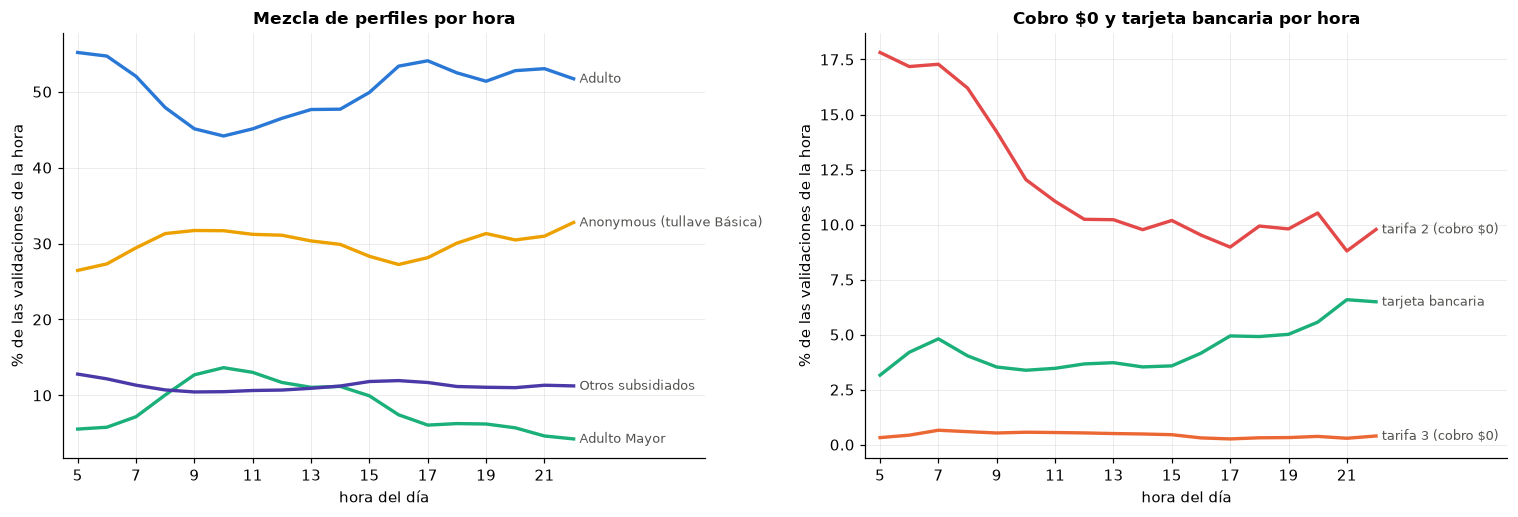

,validaciones por hora,Adulto,Adulto Mayor,Anonymous (tullave Básica),Otros subsidiados,tarifa 2 (%),bancaria (%)
hora,,,,,,,
5,130050.0,55.2,5.6,26.5,12.8,17.8,3.2
6,210692.0,54.7,5.8,27.3,12.2,17.2,4.2
7,177664.0,52.0,7.2,29.4,11.3,17.3,4.8
10,78461.0,44.2,13.6,31.7,10.5,12.0,3.4
12,81437.0,46.5,11.7,31.1,10.7,10.2,3.7
14,79114.0,47.7,11.2,29.9,11.2,9.8,3.5
17,188448.0,54.1,6.1,28.1,11.7,9.0,4.9
18,121704.0,52.5,6.3,30.1,11.2,9.9,4.9
21,18674.0,53.0,4.7,31.0,11.3,8.8,6.6


In [18]:
# QUÉ HACE: muestra cómo cambia la mezcla de usuarios a lo largo del día: (izq.) peso de cada grupo de perfil en cada hora; (der.) peso de las validaciones con tarifa 2 (cobro $0) y con tarjeta bancaria.
# CÓMO: para cada hora se divide lo que aporta el grupo entre las validaciones totales de esa hora (entre las 5:00 y las 22:59, cuando hay servicio fuerte); las líneas llevan su nombre al final.
# QUÉ MIRAR: si la mezcla es estable o cambia entre punta y valle (p. ej. Adulto Mayor sube fuera de las puntas); si el cobro $0 se concentra en alguna hora.
GRUPO = {'Adulto': 'Adulto', 'Anonymous': 'Anonymous (tullave Básica)', 'Adulto Mayor': 'Adulto Mayor'}
comp['grupo'] = comp['perfil'].map(GRUPO).fillna('Otros subsidiados')
CG = {'Adulto': '#2a78d6', 'Anonymous (tullave Básica)': '#eda100', 'Adulto Mayor': '#1baf7a', 'Otros subsidiados': '#4a3aa7'}
horas = list(range(5, 23))
tot_h = comp.groupby('hora')['validaciones'].sum().reindex(horas)
por_grupo = comp.groupby(['hora', 'grupo'])['validaciones'].sum().unstack(fill_value=0).reindex(horas) .div(tot_h, axis=0) * 100
t2 = comp[comp['Tipo_Tarifa'] == '2,0'].groupby('hora')['validaciones'].sum().reindex(horas, fill_value=0) / tot_h * 100
t3 = comp[comp['Tipo_Tarifa'] == '3,0'].groupby('hora')['validaciones'].sum().reindex(horas, fill_value=0) / tot_h * 100
ban = comp[comp['bancaria']].groupby('hora')['validaciones'].sum().reindex(horas, fill_value=0) / tot_h * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
for g, c in CG.items():
    a1.plot(horas, por_grupo[g], color=c, lw=2.2)
    a1.text(22.2, por_grupo[g].iloc[-1], g, color='#52514e', fontsize=8.5, va='center')
a1.set_xlim(4.5, 26.5); a1.set_xticks(range(5, 23, 2)); a1.set_xlabel('hora del día'); a1.set_ylabel('% de las validaciones de la hora')
a1.set_title('Mezcla de perfiles por hora')
for serie, nombre, c in [(t2, 'tarifa 2 (cobro $0)', '#e34948'), (t3, 'tarifa 3 (cobro $0)', '#eb6834'), (ban, 'tarjeta bancaria', '#1baf7a')]:
    a2.plot(horas, serie, color=c, lw=2.2); a2.text(22.2, serie.iloc[-1], nombre, color='#52514e', fontsize=8.5, va='center')
a2.set_xlim(4.5, 26.5); a2.set_xticks(range(5, 23, 2)); a2.set_xlabel('hora del día'); a2.set_ylabel('% de las validaciones de la hora')
a2.set_title('Cobro $0 y tarjeta bancaria por hora')
plt.tight_layout(); plt.savefig(FIGS / '03_perfiles_por_hora.png', bbox_inches='tight'); plt.show()

resumen_h = pd.DataFrame({'validaciones por hora': tot_h.round(0)}).join(por_grupo.round(1)).join(t2.rename('tarifa 2 (%)').round(1)).join(ban.rename('bancaria (%)').round(1))
resumen_h.loc[[5, 6, 7, 10, 12, 14, 17, 18, 21]]

In [19]:
# QUÉ HACE: compara la mezcla de usuarios entre los tipos de estación (de mañana, de tarde, doble pico) y lista las estaciones más extremas en tarifa 2 (cobro $0), tullave Básica y tarjeta bancaria.
# CÓMO: se suman las validaciones por estación y se calcula el peso de cada característica; solo estaciones activas con al menos 5.000 validaciones por día para que los porcentajes sean estables.
# QUÉ MIRAR: si las estaciones "de mañana" (portales) tienen otra mezcla que las "de tarde"; qué estaciones concentran el cobro $0 (candidatas a ser puntos de conexión con buses zonales).
por_est = comp.groupby('cod_estacion').apply(lambda g: pd.Series({
    '% tullave Básica': pct(lambda d: d['Tipo_Tarjeta'] == 'tullave Básica', g), '% Adulto Mayor': pct(lambda d: d['perfil'] == 'Adulto Mayor', g),
    '% tarifa 2 (cobro $0)': pct(lambda d: d['Tipo_Tarifa'] == '2,0', g), '% tarjeta bancaria': pct(lambda d: d['bancaria'], g)}))
est = est.drop(columns=[c for c in por_est.columns if c in est.columns]).join(por_est)

por_forma = est[est['activa']].groupby('forma')[list(por_est.columns)].mean()
por_forma['estaciones'] = est[est['activa']].groupby('forma').size()
print('Promedio por tipo de estación (cada estación pesa igual):')
display(por_forma.round(1))

grandes = est[est['val_dia'] >= 5000]
print(f"\nEstaciones con más cobro $0 (tarifa 2), entre las {len(grandes)} con >= 5.000 validaciones por día:")
display(grandes.nlargest(8, '% tarifa 2 (cobro $0)')[['nombre', 'forma', 'val_dia', '% tarifa 2 (cobro $0)', '% tullave Básica', '% tarjeta bancaria']].round(1))
print('Estaciones con más tullave Básica:')
grandes.nlargest(8, '% tullave Básica')[['nombre', 'forma', 'val_dia', '% tarifa 2 (cobro $0)', '% tullave Básica', '% tarjeta bancaria']].round(1)

Promedio por tipo de estación (cada estación pesa igual):


,% tullave Básica,% Adulto Mayor,% tarifa 2 (cobro $0),% tarjeta bancaria,estaciones
forma,,,,,
de mañana,29.0,8.3,15.5,3.8,57
de tarde,29.9,8.6,7.8,4.6,72
doble pico,28.3,10.0,17.5,4.2,20



Estaciones con más cobro $0 (tarifa 2), entre las 114 con >= 5.000 validaciones por día:


,nombre,forma,val_dia,% tarifa 2 (cobro $0),% tullave Básica,% tarjeta bancaria
cod_estacion,,,,,,
10002,Av. Primero de Mayo,de mañana,20499.2,55.4,13.8,2.4
10001,Country Sur,de mañana,13489.4,55.3,14.9,2.7
07101,CASTELLANA,de tarde,6445.3,52.3,14.6,3.2
04003,Avenida Ciudad de Cali,de mañana,8711.4,52.0,15.6,2.9
50008,Corral Portal Dorado,de mañana,30983.1,48.2,14.6,2.4
07006,General Santander,de mañana,7840.4,42.9,16.5,2.9
04100,Carrera 77,de mañana,5903.4,38.6,20.6,3.7
06000,Portal El Dorado - C.C. NUESTRO BOGOTA,doble pico,49292.4,36.3,18.6,3.8


Estaciones con más tullave Básica:


,nombre,forma,val_dia,% tarifa 2 (cobro $0),% tullave Básica,% tarjeta bancaria
cod_estacion,,,,,,
07505,LEON XIII,de mañana,12324.1,0.0,45.2,3.8
07503,SAN MATEO - C.C. UNISUR,de mañana,40366.5,0.0,43.0,3.6
02502,Terminal,de mañana,14428.5,4.7,39.9,5.2
07504,TERREROS,de mañana,27673.6,0.0,38.6,4.9
02000,Portal Norte - Unicervantes,de mañana,70314.5,5.2,38.5,4.8
09128,Temporal AV Jimenez - Inter Electricas,de tarde,10097.1,1.3,38.5,3.0
07200,Tygua-San José,de tarde,6572.9,1.1,37.5,3.8
14001,La Sabana,de tarde,6754.0,1.2,37.2,4.2


### Lectura de la sección 5

**Quiénes entran (5.1)**
- Mitad de las validaciones (51 %) son de perfil **Adulto**; casi un tercio (29 %) son **Anonymous** (tullave Básica, sin datos de la persona); 8 % Adulto Mayor; 7 % Apoyo Ciudadano (con y sin reexpedición); 3 % Adulto PV y 1,6 % Discapacidad.
- **Las tarifas 2 y 3 siempre cobran $0.** La tarifa 2 es el 17–21 % de las validaciones de cada perfil con tullave Plus y **nunca aparece en la tullave Básica (Anonymous)**; la tarifa 3 es menor (0,5–0,9 %) y también solo en Plus. Esto es coherente con que el cobro $0 por transbordo exista solo con tarjeta personalizada, pero **todavía es una interpretación**: se confirmaría con el saldo antes y después (otra sección, si se usa).
- Un **10,6 % de las validaciones Anonymous y un 9,9 % de Adulto PV** vienen de medios que no son Bogotá Card (tarjetas bancarias). En total, la tarjeta bancaria es ~4 % del sistema. Queda como pregunta abierta por qué esos medios se registran con esos perfiles.

**Cambio por hora (5.2)**
- La mezcla **casi no cambia** entre punta y valle: Adulto ronda 44–55 % y Anonymous 27–32 % a todas horas. Quien llena las puntas es el mismo tipo de usuario que llena el resto del día, solo que más.
- Dos cosas sí cambian: el **Adulto Mayor** pasa de 5–6 % en la madrugada a 13–14 % a las 10 a. m. (viajan en el valle, no en la punta) y la **tarifa 2 (cobro $0)** baja de ~17–18 % a las 5–7 a. m. a ~9–10 % en la tarde. La tarjeta bancaria sube un poco por la noche (de 3 % a 6,6 % a las 9 p. m.).

**Por tipo de estación (5.3)**
- La mezcla de tullave Básica y Adulto Mayor es parecida entre estaciones "de mañana", "de tarde" y de "doble pico" (29–30 % y 8–10 %). **La diferencia está en la tarifa 2**: 15,5 % en las de mañana, 17,5 % en las de doble pico y solo 7,8 % en las de tarde.
- Algunas estaciones concentran el cobro $0 de forma muy marcada: **Av. Primero de Mayo y Country Sur (55 %), Castellana (52 %), Av. Ciudad de Cali (52 %) y el Corral Portal Dorado (48 %)**. Son candidatas a ser puntos de **conexión con otros buses**, hipótesis que se revisa con el mapa (sección 6).
- Las estaciones con más tullave Básica son León XIII (45 %), San Mateo (43 %), Terminal (40 %), Terreros (39 %) y Portal Norte (38,5 %): casi todas en la periferia (Soacha y el norte).

**Qué se concluye para la pregunta del proyecto:** el **perfil del usuario no explica cuándo hay presión** (la mezcla es estable en las puntas), pero sí dos **características de la estación** que se guardan para el modelo: `% tarifa 2` (estación de conexión) y `% tullave Básica`. La pregunta "¿dónde y cuándo?" sigue dependiendo del volumen y de la forma horaria (secciones 3 y 4).

## 6. ¿Dónde está la demanda en la ciudad? Mapa por franjas horarias

Se ubican las estaciones con sus coordenadas (archivo oficial de estaciones) y se dibuja la demanda de **cada franja del día**. Son cinco franjas, definidas con lo que se vio en las secciones 3 y 4:

| Franja | Horas | Qué es |
|---|---|---|
| madrugada | 0:00 - 4:59 | arranque del servicio |
| punta mañana | 5:00 - 8:59 | primer pico |
| valle | 9:00 - 15:59 | demanda baja y estable |
| punta tarde | 16:00 - 19:59 | segundo pico |
| noche | 20:00 - 23:59 | cierre |

La medida es **validaciones por hora** dentro de la franja (total de la franja dividido entre sus horas), para que franjas de distinta duración se puedan comparar. El tamaño del círculo es la demanda; en todos los mapas la escala es la misma.

Se contrastan dos hipótesis que quedaron abiertas: que las estaciones **"de mañana" están en la periferia** (sección 4) y que las estaciones con **mucho cobro $0 (tarifa 2) son puntos de conexión** (sección 5). No se usa mapa base (no se descargan datos de internet): la forma de la ciudad se reconoce por la ubicación de las estaciones.

In [20]:
# QUÉ HACE: pone coordenadas a las estaciones, define las cinco franjas horarias y calcula las validaciones por hora de cada estación en cada franja.
# CÓMO: latitud y longitud salen del archivo oficial (y del segundo archivo de estaciones como respaldo); las estaciones sin coordenadas se listan y no se dibujan; por franja se promedian las horas de por_est_hora.
# QUÉ MIRAR: cuántas estaciones y qué % de la demanda quedan sin coordenadas (se declara como limitación); cómo se reparte la demanda del sistema entre franjas; qué estaciones lideran cada franja.
BANDAS = {'madrugada': (0, 4), 'manana': (5, 8), 'valle': (9, 15), 'tarde': (16, 19), 'noche': (20, 23)}
TIT = {'madrugada': 'madrugada (0-4 h)', 'manana': 'punta mañana (5-8 h)', 'valle': 'valle (9-15 h)', 'tarde': 'punta tarde (16-19 h)', 'noche': 'noche (20-23 h)'}
ui = pd.read_csv('../data/raw/estaciones/estaciones_troncales_ui.csv', dtype=str, encoding='utf-8-sig').set_index('num_est')
est['lat'] = pd.to_numeric(oficial['latitud_estacion'].reindex(est.index)).fillna(pd.to_numeric(ui['latitud'].reindex(est.index)))
est['lon'] = pd.to_numeric(oficial['longitud_estacion'].reindex(est.index)).fillna(pd.to_numeric(ui['longitud'].reindex(est.index)))
for k, (a, z) in BANDAS.items():
    est[f'vh_{k}'] = por_est_hora.loc[est.index, a:z].mean(axis=1)                  # validaciones por hora en la franja (promedio de un día hábil)

sin = est[est['lat'].isna() & est['activa']]
print(f"Estaciones activas sin coordenadas: {len(sin)} de {int(est['activa'].sum())}, que reúnen el {sin['val_dia'].sum() / est['val_dia'].sum() * 100:.1f} % de las validaciones.")
display(sin[['nombre', 'val_dia', 'forma']].round(0).head(8))

fr = pd.DataFrame({TIT[k]: [est[f'vh_{k}'].sum(), est[f'vh_{k}'].sum() * (z - a + 1) / est['val_dia'].sum() * 100]
                   for k, (a, z) in BANDAS.items()}, index=['validaciones por hora (sistema)', '% de las validaciones del día']).T
display(fr.round(1))
top5 = pd.DataFrame({TIT[k]: [f"{n[:24]} ({v:,.0f})" for n, v in zip(est.nlargest(5, f'vh_{k}')['nombre'], est.nlargest(5, f'vh_{k}')[f'vh_{k}'])] for k in BANDAS}, index=range(1, 6))
top5.index.name = 'puesto'
top5

Estaciones activas sin coordenadas: 14 de 149, que reúnen el 8.7 % de las validaciones.


,nombre,val_dia,forma
cod_estacion,,,
50008,Corral Portal Dorado,30983.0,de mañana
09127,Temporal Flores,25298.0,de tarde
09126,Temporal Marly,22034.0,de tarde
09125,Temporal Calle 57,19031.0,de tarde
09130,Temporal Avenida 39,18408.0,de tarde
57503,Ampliacion San Mateo,17748.0,de mañana
09128,Temporal AV Jimenez - Inter Electricas,10097.0,de tarde
09005,Danubio,6738.0,de mañana


,validaciones por hora (sistema),% de las validaciones del día
madrugada (0-4 h),8596.2,2.3
punta mañana (5-8 h),159096.2,34.4
valle (9-15 h),83391.1,31.5
punta tarde (16-19 h),133193.9,28.8
noche (20-23 h),14094.1,3.0


,madrugada (0-4 h),punta mañana (5-8 h),valle (9-15 h),punta tarde (16-19 h),noche (20-23 h)
puesto,,,,,
1,"Portal Américas (1,231)","Portal Américas (10,494)","Portal Norte - Unicervan (3,249)","Calle 100 - Marketmedios (5,440)",Heroes - Gel hada (398)
2,SAN MATEO - C.C. UNISUR (846),"Portal Suba (8,363)","Portal Américas (2,554)","Portal Norte - Unicervan (4,053)",Calle 100 - Marketmedios (390)
3,Cabecera Usme (824),"Portal Sur JFK Coop. Fin (8,304)","Cabecera Calle 80 (2,376)","Portal El Dorado - C.C. (3,547)",Temporal Flores (388)
4,Portal Sur JFK Coop. Fin (718),"Cabecera Usme (7,539)","Calle 100 - Marketmedios (2,178)","Museo Nacional - FNG (3,136)",EL CAMPIN (380)
5,Portal Tunal (605),"Portal Norte - Unicervan (7,386)","Portal Suba (2,132)","Temporal Flores (3,114)",Portal El Dorado - C.C. (361)


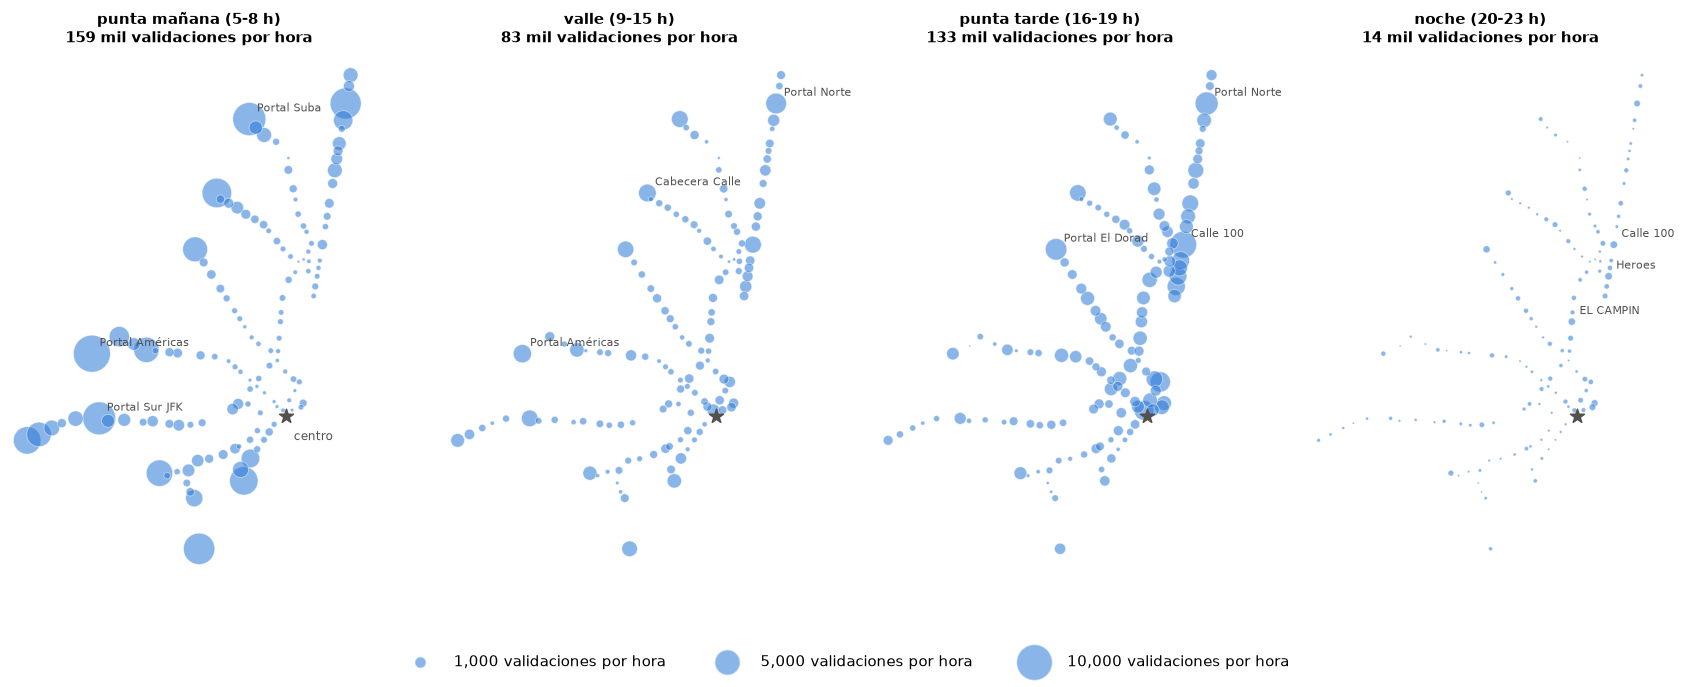

Estaciones dibujadas: 136 (91.3 % de las validaciones)


In [21]:
# QUÉ HACE: dibuja el mapa de las estaciones en cuatro franjas (punta mañana, valle, punta tarde y noche); el tamaño del círculo es la demanda por hora de esa franja.
# CÓMO: longitud en el eje horizontal y latitud en el vertical, con la misma escala de tamaño en los cuatro paneles; la estrella gris marca el centro (Plaza de Bolívar) como referencia; se rotulan las 3 estaciones más grandes de cada franja.
# QUÉ MIRAR: cómo los círculos grandes de la periferia (portales) dominan la punta de la mañana y cómo en la punta de la tarde pesan más las estaciones del centro; el valle y la noche son mucho más parejos y pequeños.
mapa = est.dropna(subset=['lat']).copy()
CENTRO = (-74.0760, 4.5981)                                                           # Plaza de Bolívar (referencia)
paneles = ['manana', 'valle', 'tarde', 'noche']
ESC = 1 / 18                                                                          # tamaño del círculo = validaciones por hora * ESC

fig, axes = plt.subplots(1, 4, figsize=(15.5, 6.2), sharex=True, sharey=True)
for ax, k in zip(axes, paneles):
    ax.scatter(mapa['lon'], mapa['lat'], s=mapa[f'vh_{k}'] * ESC + 1.5, color=COL['hábil'], alpha=0.55, edgecolors='white', linewidths=0.5)
    ax.scatter(*CENTRO, marker='*', s=90, color='#52514e', zorder=5)
    for _, r in mapa.nlargest(3, f'vh_{k}').iterrows():
        ax.annotate(r['nombre'].split(' - ')[0][:15], (r['lon'], r['lat']), xytext=(5, 5), textcoords='offset points', fontsize=7.5, color='#52514e')
    ax.set_title(f"{TIT[k]}\n{est[f'vh_{k}'].sum() / 1e3:,.0f} mil validaciones por hora", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_aspect('equal', adjustable='box')
    for s in ax.spines.values(): s.set_visible(False)
axes[0].text(CENTRO[0] + 0.004, CENTRO[1] - 0.012, 'centro', fontsize=8, color='#52514e')
refs = [1000, 5000, 10000]
fig.legend([plt.scatter([], [], s=v * ESC + 1.5, color=COL['hábil'], alpha=0.55, edgecolors='white') for v in refs], [f"{v:,} validaciones por hora" for v in refs],
           ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.02), frameon=False, labelspacing=1.2, handletextpad=1.2, columnspacing=3)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig(FIGS / '03_mapa_franjas.png', bbox_inches='tight'); plt.show()
print(f"Estaciones dibujadas: {len(mapa)} ({mapa['val_dia'].sum() / est['val_dia'].sum() * 100:.1f} % de las validaciones)")

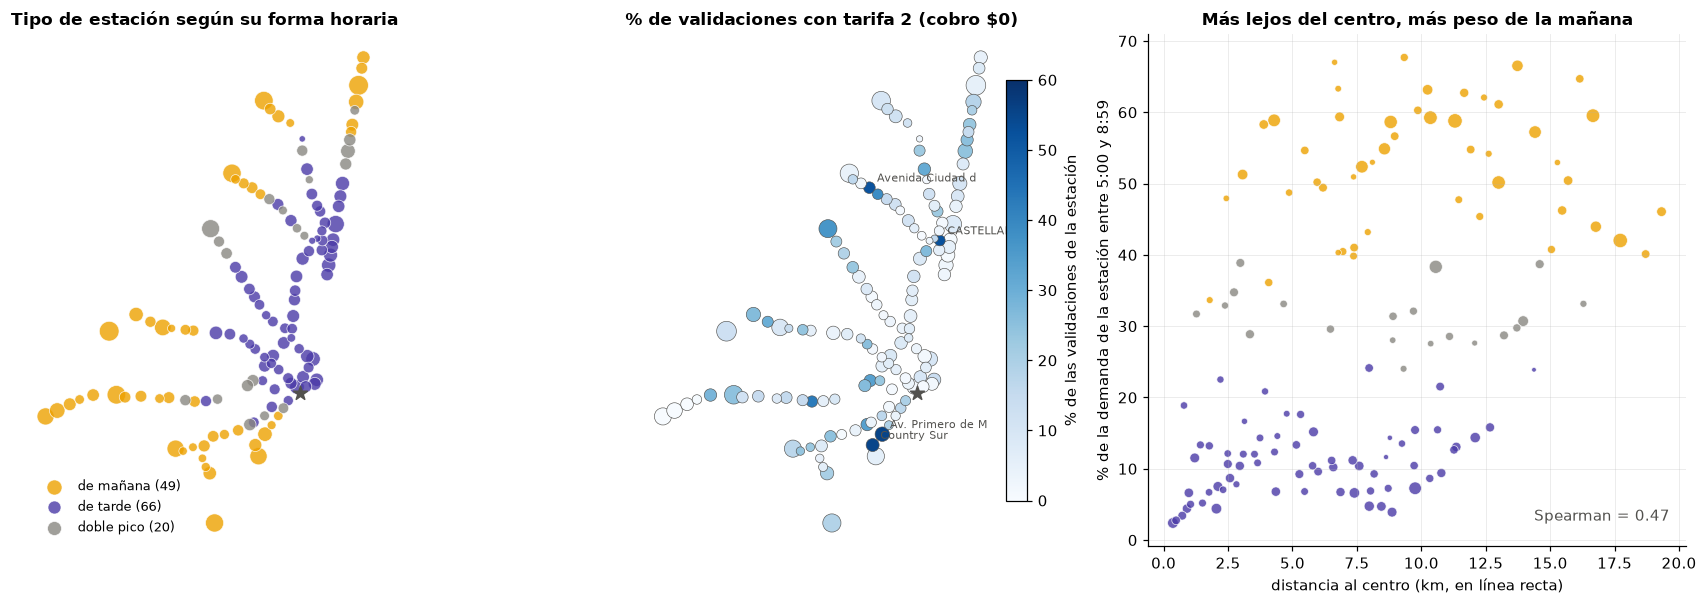

,estaciones,km_promedio,km_mediana,pct_tarifa2
forma,,,,
de mañana,49,10.1,9.3,16.2
de tarde,66,5.7,5.3,8.2
doble pico,20,8.8,9.5,17.5


In [22]:
# QUÉ HACE: contrasta dos hipótesis con el mapa: (1) las estaciones "de mañana" están lejos del centro; (2) el cobro $0 (tarifa 2) se concentra en ciertas estaciones de conexión.
# CÓMO: izquierda, mapa coloreado por el tipo de estación (de mañana, de tarde, doble pico); centro, mapa coloreado por el % de tarifa 2; derecha, distancia al centro contra % de la demanda que cae en la mañana (Spearman al pie).
# QUÉ MIRAR: si los puntos amarillos (de mañana) quedan en los bordes del mapa; si hay "manchas" de cobro $0 alto en algunas zonas; la correlación de Spearman entre distancia y % de mañana.
def km(lon, lat, lon0=CENTRO[0], lat0=CENTRO[1]):                                       # distancia aproximada al centro (haversine)
    f = np.pi / 180; a = np.sin((lat - lat0) * f / 2) ** 2 + np.cos(lat * f) * np.cos(lat0 * f) * np.sin((lon - lon0) * f / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))
mapa['km_centro'] = km(mapa['lon'], mapa['lat'])
m_act = mapa[mapa['activa']]

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(16, 5.6), gridspec_kw={'width_ratios': [1, 1, 1.15]})
for f, c in CF.items():
    s = m_act[m_act['forma'] == f]
    a1.scatter(s['lon'], s['lat'], s=np.sqrt(s['val_dia']) / 1.6, color=c, alpha=0.8, edgecolors='white', linewidths=0.5, label=f"{f} ({len(s)})")
a1.set_title('Tipo de estación según su forma horaria'); a1.legend(loc='lower left', fontsize=8.5)
sc = a2.scatter(m_act['lon'], m_act['lat'], s=np.sqrt(m_act['val_dia']) / 1.6, c=m_act['% tarifa 2 (cobro $0)'], cmap='Blues', vmin=0, vmax=60, edgecolors='#52514e', linewidths=0.4)
a2.set_title('% de validaciones con tarifa 2 (cobro $0)'); fig.colorbar(sc, ax=a2, fraction=0.045, pad=0.02).set_label('% de las validaciones de la estación')
for _, r in m_act.nlargest(4, '% tarifa 2 (cobro $0)').iterrows():
    a2.annotate(r['nombre'][:16], (r['lon'], r['lat']), xytext=(5, 4), textcoords='offset points', fontsize=7.5, color='#52514e')
for a in (a1, a2):
    a.scatter(*CENTRO, marker='*', s=90, color='#52514e', zorder=5)
    a.set_xticks([]); a.set_yticks([]); a.grid(False); a.set_aspect('equal', adjustable='box')
    for s_ in a.spines.values(): s_.set_visible(False)
for f, c in CF.items():
    s = m_act[m_act['forma'] == f]
    a3.scatter(s['km_centro'], s['pct_manana'], s=np.sqrt(s['val_dia']) / 3, color=c, alpha=0.8, edgecolors='white', linewidths=0.5)
rho = m_act['km_centro'].corr(m_act['pct_manana'], method='spearman')
a3.set_xlabel('distancia al centro (km, en línea recta)'); a3.set_ylabel('% de la demanda de la estación entre 5:00 y 8:59')
a3.set_title('Más lejos del centro, más peso de la mañana'); a3.text(0.97, 0.05, f"Spearman = {rho:.2f}", transform=a3.transAxes, ha='right', fontsize=10, color='#52514e')
plt.tight_layout(); plt.savefig(FIGS / '03_mapa_formas_y_tarifa2.png', bbox_inches='tight'); plt.show()

dist = m_act.groupby('forma').agg(estaciones=('nombre', 'size'), km_promedio=('km_centro', 'mean'), km_mediana=('km_centro', 'median'), pct_tarifa2=('% tarifa 2 (cobro $0)', 'mean'))
dist.round(1)

### Lectura de la sección 6

**Franjas del día**
- Las dos puntas son la mayor parte de la presión: la **punta de la mañana** mueve 159 mil validaciones por hora (34 % del día en solo 4 horas) y la **punta de la tarde**, 133 mil por hora (29 % en 4 horas). El **valle** (7 horas) mueve 83 mil por hora y la **madrugada** y la **noche** son marginales (9 mil y 14 mil por hora).
- **En la mañana la demanda está concentrada en pocas estaciones grandes de la periferia**: Américas (10,5 mil por hora), Suba (8,4 mil), Sur (8,3 mil), Usme (7,5 mil) y Norte (7,4 mil). **En la tarde está más repartida y es menos extrema**: el máximo es Calle 100 con 5,4 mil por hora, seguida de Portal Norte, El Dorado y Museo Nacional (3,1 a 4,1 mil). Por la noche ninguna estación pasa de 400 validaciones por hora.
- Para el apoyo logístico esto sugiere dos escenarios distintos: **pocos puntos con mucha carga en la mañana** (los portales) y **más puntos con carga moderada en la tarde** (centro y norte).

**¿Las estaciones "de mañana" están en la periferia? (hipótesis de la sección 4)**
- **Se cumple en parte.** Las estaciones "de mañana" están a una mediana de **9,3 km** del centro, las "de tarde" a **5,3 km** y las de doble pico a 9,5 km. La correlación entre distancia al centro y peso de la mañana es **moderada (Spearman 0,47)**: la distancia ayuda, pero no lo explica todo (hay estaciones cercanas al centro con perfil de mañana y estaciones lejanas con perfil de tarde). La distancia es en línea recta a un punto, que es una referencia simple, no el recorrido real.

**¿El cobro $0 marca estaciones de conexión? (hipótesis de la sección 5)**
- El cobro $0 alto **no forma zonas, sino estaciones puntuales**: Av. Primero de Mayo, Country Sur, Castellana y Av. Ciudad de Cali superan el 50 %, mientras sus vecinas están muy por debajo. Eso es compatible con estaciones donde se conectan otros buses, pero **no se puede confirmar sin datos del servicio zonal**, que el proyecto no usa. Queda como hipótesis y como característica de la estación (`% tarifa 2`).

**Limitación importante:** hay **14 estaciones activas sin coordenadas** (8,7 % de las validaciones): estaciones temporales (Flores, Marly, Calle 57, Avenida 39, Av. Jiménez), el Corral Portal Dorado, Ampliación San Mateo y Danubio. Casi todas las temporales son "de tarde" y del centro, así que **el mapa subestima la punta de la tarde**. No se inventan coordenadas: se declara la limitación y los resultados que no dependen del mapa (rankings, formas, tablas) las incluyen.

## 7. ¿La gente vuelve en TransMilenio? El viaje de ida y de regreso por tarjeta

Cada validación trae el **número de tarjeta anonimizado** (un código, no una persona identificable). Agrupando por tarjeta y día se reconstruye, de forma aproximada, el **viaje de ida y el de regreso**:

- la **primera validación del día** de una tarjeta es el origen de su viaje (la estación donde entró);
- la **última** es, normalmente, el regreso: la estación donde vuelve a entrar es el destino aproximado de la ida.

Preguntas: ¿cuántas veces valida una tarjeta por día? ¿Qué parte de quienes salen en la mañana vuelve en TransMilenio en la tarde? ¿Desde dónde vuelven? ¿Hay usuarios habituales que concentran la demanda?

**Limitaciones que hay que tener presentes:** (1) el destino es **inferido, no observado** (solo se ve dónde se *entra*); (2) dentro de la troncal se puede cambiar de ruta sin volver a validar, así que un viaje con transbordo interno cuenta como una sola validación; (3) quien regresa por otro medio (bus zonal, moto, a pie) aparece "sin vuelta"; (4) una tarjeta puede usarla más de una persona. Por privacidad **solo se guardan agregados**: nunca se imprimen ni se suben códigos de tarjeta.

In [23]:
# QUÉ HACE: resume cada tarjeta en cada día hábil: cuántas validaciones hizo, a qué minuto fue la primera y la última y en qué estación.
# CÓMO: cada archivo del consolidado se procesa por separado (tres a la vez) y se reduce a una fila por tarjeta y día; el número de tarjeta se convierte a un código numérico (hash) para ocupar menos memoria; la suma de validaciones debe dar las 25,931,574 de los días hábiles.
# QUÉ MIRAR: el número de filas (tarjetas-día), cuántas tarjetas distintas hay y las validaciones promedio por tarjeta en un día; la suma debe cuadrar.
import dask.delayed
fecha_cod = {f: k for k, f in enumerate(habiles)}

def resumen_tarjeta_dia(pdf):
    pdf = pdf[pdf['Fecha_Transaccion'].str[:10].isin(habiles)]
    d = pd.DataFrame({'key': pd.util.hash_pandas_object(pdf['Numero_Tarjeta'], index=False).values,
                      'fecha': pdf['Fecha_Transaccion'].str[:10].map(fecha_cod).astype('int8').values,
                      't': (pdf['Fecha_Transaccion'].str[11:13].astype('int16') * 60 + pdf['Fecha_Transaccion'].str[14:16].astype('int16')).values,
                      'est': pdf['Estacion_Parada'].str[1:6].astype('int32').values})
    d = d.sort_values(['key', 'fecha', 't'], kind='stable')
    out = d.groupby(['key', 'fecha'], sort=False).agg(n=('t', 'size'), t1=('t', 'first'), t2=('t', 'last'), e1=('est', 'first'), e2=('est', 'last')).reset_index()
    return out.astype({'n': 'int16', 't1': 'int16', 't2': 'int16', 'e1': 'int32', 'e2': 'int32'})

t0 = time.perf_counter()
vt = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion', 'Estacion_Parada', 'Numero_Tarjeta'])
partes = dask.compute(*[dask.delayed(resumen_tarjeta_dia)(p) for p in vt.to_delayed()], scheduler='threads', num_workers=3)
tj = pd.concat([p for p in partes if len(p)], ignore_index=True)
dup = tj.duplicated(['key', 'fecha']).sum()                      # una tarjeta-día partida entre dos archivos (solo en la frontera de medianoche)
if dup:
    tj = tj.sort_values(['key', 'fecha', 't1']).groupby(['key', 'fecha'], sort=False).agg(n=('n', 'sum'), t1=('t1', 'first'), t2=('t2', 'last'), e1=('e1', 'first'), e2=('e2', 'last')).reset_index()
del partes
print(f"Resumen por tarjeta-día en {time.perf_counter() - t0:.0f} s | tarjeta-días partidas entre archivos: {dup:,}")
assert tj['n'].sum() == por_minuto.sum(), 'no cuadran las validaciones'
tj['t1'] = tj['t1'].astype('int16'); tj['n'] = tj['n'].astype('int16')
print(f"{len(tj):,} tarjeta-días | {tj['key'].nunique():,} tarjetas distintas | {tj['n'].sum() / len(tj):.2f} validaciones por tarjeta y día | memoria {tj.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
tj.head(3).drop(columns='key')

Resumen por tarjeta-día en 73 s | tarjeta-días partidas entre archivos: 210


15,410,480 tarjeta-días | 3,484,936 tarjetas distintas | 1.68 validaciones por tarjeta y día | memoria 354 MB


,fecha,n,t1,t2,e1,e2
0,10,1,936,936,4003,4003
1,6,2,860,1074,6108,2303
2,12,1,1282,1282,6100,6100


De las tarjetas que validan por primera vez en la punta de la mañana (5:00-8:59): 52.4 % vuelve a validar después de las 15:00; 29.8 % valida una sola vez en el día.


De las tarjetas cuya última validación cae en la punta de la tarde (16:00-19:59): 54.1 % también validó en la punta de la mañana; 25.3 % solo validó esa vez.


,tarjeta-días,% de los tarjeta-días,% de las validaciones
validaciones por tarjeta en el día,,,
1,6688272,43.4,25.8
2,7378466,47.9,56.9
3,1007505,6.5,11.7
4 o más,336237,2.2,5.6


,tarjeta_dias,validaciones,% de los tarjeta-días,% de las validaciones
patron,,,,
"2+ validaciones, otro patrón",5059641,11333098,32.8,43.7
ida y vuelta: mañana -> tarde,3662567,7910204,23.8,30.5
una sola validación,6688272,6688272,43.4,25.8


Duración de la jornada (primera a última validación) en ida y vuelta: mediana 10.7 h, percentiles 25-75 de 10.0 a 11.4 h; misma estación de ida y vuelta: 1.1 %.


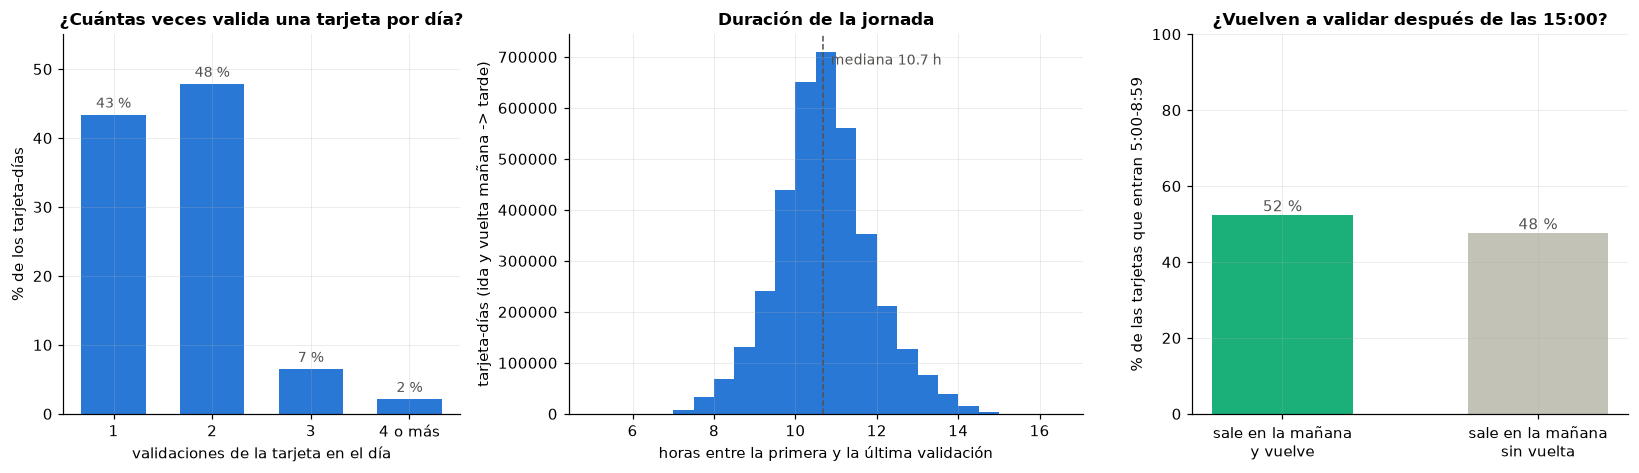

In [24]:
# QUÉ HACE: cuenta cuántas veces valida una tarjeta por día y clasifica su día en: una sola validación, ida y vuelta (mañana -> tarde) u otro patrón; y calcula qué parte de quienes salen en la mañana vuelve.
# CÓMO: mañana = primera validación entre 5:00 y 8:59; tarde = última validación entre 16:00 y 19:59 (con al menos 2 validaciones); la "vuelta" se mide por la hora de la última validación (>= 15:00).
# QUÉ MIRAR: el % de tarjeta-días con 1, 2, 3 o más validaciones; cuántas tienen el patrón mañana -> tarde; de quienes entran en la punta de la mañana, cuántos vuelven a validar en la tarde; la duración típica de la jornada.
AM, PM = (300, 540), (960, 1200)
en_am = tj['t1'].between(AM[0], AM[1] - 1); fin_pm = tj['t2'].between(PM[0], PM[1] - 1)
tj['patron'] = np.select([tj['n'] == 1, en_am & fin_pm & (tj['n'] >= 2)],
                         ['una sola validación', 'ida y vuelta: mañana -> tarde'], default='2+ validaciones, otro patrón')

cuantas = tj['n'].clip(upper=4).map({1: '1', 2: '2', 3: '3', 4: '4 o más'}).value_counts().reindex(['1', '2', '3', '4 o más'])
tabla_n = pd.DataFrame({'tarjeta-días': cuantas, '% de los tarjeta-días': cuantas / len(tj) * 100})
tabla_n['% de las validaciones'] = tj.groupby(tj['n'].clip(upper=4).map({1: '1', 2: '2', 3: '3', 4: '4 o más'}))['n'].sum().reindex(tabla_n.index) / tj['n'].sum() * 100
tabla_n.index.name = 'validaciones por tarjeta en el día'

pat = tj.groupby('patron').agg(tarjeta_dias=('n', 'size'), validaciones=('n', 'sum'))
pat['% de los tarjeta-días'] = pat['tarjeta_dias'] / len(tj) * 100
pat['% de las validaciones'] = pat['validaciones'] / tj['n'].sum() * 100
vuelve = (tj['n'] >= 2) & (tj['t2'] >= 900)
sale_am = tj[en_am]
print(f"De las tarjetas que validan por primera vez en la punta de la mañana (5:00-8:59): {(vuelve[en_am]).mean() * 100:.1f} % vuelve a validar después de las 15:00; {(sale_am['n'] == 1).mean() * 100:.1f} % valida una sola vez en el día.")
tarde_fin = tj[fin_pm]
print(f"De las tarjetas cuya última validación cae en la punta de la tarde (16:00-19:59): {((tarde_fin['n'] >= 2) & tarde_fin['t1'].between(AM[0], AM[1] - 1)).mean() * 100:.1f} % también validó en la punta de la mañana; {(tarde_fin['n'] == 1).mean() * 100:.1f} % solo validó esa vez.")
display(tabla_n.round(1)); display(pat.round(1))

iv = tj[tj['patron'] == 'ida y vuelta: mañana -> tarde']
dur = (iv['t2'] - iv['t1']) / 60
print(f"Duración de la jornada (primera a última validación) en ida y vuelta: mediana {dur.median():.1f} h, percentiles 25-75 de {dur.quantile(.25):.1f} a {dur.quantile(.75):.1f} h; misma estación de ida y vuelta: {(iv['e1'] == iv['e2']).mean() * 100:.1f} %.")

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={'width_ratios': [1, 1.3, 1.1]})
a1.bar(tabla_n.index, tabla_n['% de los tarjeta-días'], color=COL['hábil'], width=0.65)
for k, v in enumerate(tabla_n['% de los tarjeta-días']): a1.text(k, v + 1, f"{v:.0f} %", ha='center', fontsize=9, color='#52514e')
a1.set_xlabel('validaciones de la tarjeta en el día'); a1.set_ylabel('% de los tarjeta-días'); a1.set_title('¿Cuántas veces valida una tarjeta por día?'); a1.set_ylim(0, tabla_n['% de los tarjeta-días'].max() * 1.15)
a2.hist(dur, bins=np.arange(5, 17, 0.5), color=COL['hábil'])
a2.axvline(dur.median(), color='#52514e', lw=1, ls='--'); a2.text(dur.median() + 0.2, a2.get_ylim()[1] * 0.92, f"mediana {dur.median():.1f} h", fontsize=9, color='#52514e')
a2.set_xlabel('horas entre la primera y la última validación'); a2.set_ylabel('tarjeta-días (ida y vuelta mañana -> tarde)'); a2.set_title('Duración de la jornada')
hv = pd.Series({'sale en la mañana\ny vuelve': vuelve[en_am].mean() * 100, 'sale en la mañana\nsin vuelta': 100 - vuelve[en_am].mean() * 100})
a3.bar(hv.index, hv.values, color=['#1baf7a', '#c3c2b7'], width=0.55)
for k, v in enumerate(hv.values): a3.text(k, v + 1, f"{v:.0f} %", ha='center', fontsize=10, color='#52514e')
a3.set_ylabel('% de las tarjetas que entran 5:00-8:59'); a3.set_title('¿Vuelven a validar después de las 15:00?'); a3.set_ylim(0, 100)
plt.tight_layout(); plt.savefig(FIGS / '03_ida_y_vuelta.png', bbox_inches='tight'); plt.show()

In [25]:
# QUÉ HACE: (1) mide los usuarios habituales (cuántos días de los 14 aparece cada tarjeta) y (2) cruza la estación de la mañana con la estación de la tarde en los viajes de ida y vuelta, por tipo de estación y por pares de estaciones.
# CÓMO: (1) días distintos en que aparece cada tarjeta; (2) en cada ida y vuelta mañana -> tarde se toma la estación de la primera validación (origen) y la de la última (donde vuelve a entrar = destino aproximado).
# QUÉ MIRAR: qué % de las tarjetas son habituales (8+ días) y cuánta demanda concentran; si quienes salen de estaciones "de mañana" (periferia) vuelven a entrar en estaciones "de tarde" (centro); los 10 pares de estaciones más frecuentes.
dias_act = tj.groupby('key')['fecha'].nunique()
gr = pd.cut(dias_act, [0, 2, 7, 11, 14], labels=['1-2 días', '3-7 días', '8-11 días', '12-14 días'])
val_t = tj.groupby('key')['n'].sum()
hab = pd.DataFrame({'tarjetas': gr.value_counts().sort_index(), 'validaciones': val_t.groupby(gr).sum()})
hab['% de las tarjetas'] = hab['tarjetas'] / hab['tarjetas'].sum() * 100
hab['% de las validaciones'] = hab['validaciones'] / hab['validaciones'].sum() * 100
hab['validaciones por tarjeta y día'] = hab['validaciones'] / tj.groupby(gr.reindex(tj['key']).values, observed=True).size().reindex(hab.index).values
hab.index.name = 'días con validaciones (de 14)'
display(hab.round(1))

forma_cod = {int(c): f for c, f in est['forma'].items()}
nom_cod = {int(c): n for c, n in est['nombre'].items()}
iv = iv.assign(f1=iv['e1'].map(forma_cod), f2=iv['e2'].map(forma_cod))
cruce = pd.crosstab(iv['f1'], iv['f2'], normalize='all') * 100
cruce.index.name = 'estación de la mañana'; cruce.columns.name = 'estación donde vuelve a entrar'
print(f"Ida y vuelta mañana -> tarde: {len(iv):,} tarjeta-días. Distribución según el tipo de estación de origen (fila) y de regreso (columna), % del total:")
display(cruce.round(1))
print('Dado el tipo de estación de origen, ¿dónde vuelve a entrar? (cada fila suma 100 %)')
display((pd.crosstab(iv['f1'], iv['f2'], normalize='index') * 100).round(1))

pares = iv.groupby(['e1', 'e2']).size().rename('viajes_por_dia').div(len(habiles)).reset_index().nlargest(10, 'viajes_por_dia')
pares['origen (mañana)'] = pares['e1'].map(nom_cod).str[:26]; pares['regreso (tarde)'] = pares['e2'].map(nom_cod).str[:26]
pares.index = range(1, 11)
print('Los 10 pares de estaciones más frecuentes (viajes de ida y vuelta por día hábil):')
pares[['origen (mañana)', 'regreso (tarde)', 'viajes_por_dia']].round(0)

,tarjetas,validaciones,% de las tarjetas,% de las validaciones,validaciones por tarjeta y día
días con validaciones (de 14),,,,,
1-2 días,1677021,3697582,48.1,14.3,1.7
3-7 días,1051004,7690141,30.2,29.7,1.6
8-11 días,400986,6226954,11.5,24.0,1.7
12-14 días,355925,8316897,10.2,32.1,1.8


Ida y vuelta mañana -> tarde: 3,662,567 tarjeta-días. Distribución según el tipo de estación de origen (fila) y de regreso (columna), % del total:


estación donde vuelve a entrar,de mañana,de tarde,doble pico,sin uso
estación de la mañana,,,,
de mañana,10.8,63.6,9.7,0.0
de tarde,2.0,5.2,0.9,0.0
doble pico,1.2,6.0,0.7,0.0
sin uso,0.0,0.0,0.0,0.0


Dado el tipo de estación de origen, ¿dónde vuelve a entrar? (cada fila suma 100 %)


f2,de mañana,de tarde,doble pico,sin uso
f1,,,,
de mañana,12.8,75.7,11.5,0.0
de tarde,24.5,64.3,11.2,0.0
doble pico,15.2,75.4,9.4,0.0
sin uso,14.6,82.1,2.0,1.3


Los 10 pares de estaciones más frecuentes (viajes de ida y vuelta por día hábil):


,origen (mañana),regreso (tarde),viajes_por_dia
1,Portal Norte - Unicervante,Calle 100 - Marketmedios,1278.0
2,Portal Suba,NIZA - CALLE 127,1026.0
3,TERREROS,Calle 100 - Marketmedios,879.0
4,Portal Américas,Calle 100 - Marketmedios,853.0
5,Cabecera Calle 80,Calle 100 - Marketmedios,830.0
6,Portal Sur JFK Coop. Finan,Calle 100 - Marketmedios,800.0
7,Portal Suba,SUBA - CALLE 100,780.0
8,SAN MATEO - C.C. UNISUR,Calle 100 - Marketmedios,756.0
9,Portal Américas,Pradera – Plaza Central,711.0
10,Portal Américas,Museo Nacional - FNG,674.0


### Lectura de la sección 7

**Cuántas veces valida una tarjeta (7.2)**
- En los 14 días hábiles hay **15,4 millones de tarjeta-días** de **3,5 millones de tarjetas distintas**, con **1,68 validaciones por tarjeta y día**.
- **El 48 % de los tarjeta-días tiene exactamente 2 validaciones** (el patrón de ida y vuelta) y el 43 % tiene una sola; el 9 % tiene 3 o más. Por validaciones: las tarjetas con 2 validaciones aportan el 57 % de la demanda.

**¿Todos vuelven en TransMilenio? No.**
- De las tarjetas que entran por primera vez en la punta de la mañana (5:00-8:59), **el 52 % vuelve a validar después de las 15:00**, el **30 % valida una sola vez en el día** y el 18 % restante valida más de una vez pero no en la tarde.
- Mirado al revés: de las tarjetas cuya última validación cae en la punta de la tarde, el 54 % ya había validado en la punta de la mañana y el 25 % solo validó esa vez (llegó a TransMilenio en la tarde sin haberlo usado por la mañana).
- El patrón completo **mañana -> tarde** es el **24 % de los tarjeta-días** y el **30 % de las validaciones**. Quien "no vuelve" puede haber regresado por otro medio (bus zonal, a pie, moto), haber usado un transbordo interno o no haber regresado ese día: con estos datos no se puede distinguir.
- La **duración de la jornada** (primera a última validación) tiene una mediana de **10,7 horas** (la mitad de los casos entre 10,0 y 11,4 h), una jornada laboral o de estudio típica. Su histograma tiene **forma de campana**, un buen candidato para el notebook del Teorema del Límite Central.

**Usuarios habituales (7.3)**
- La demanda se apoya en un grupo pequeño de tarjetas constantes: el **10 % de las tarjetas aparece 12 a 14 de los 14 días y aporta el 32 % de las validaciones**; con 8 o más días son el 22 % de las tarjetas y el 56 % de las validaciones. En el otro extremo, el 48 % de las tarjetas aparece solo 1 o 2 días (14 % de las validaciones: ocasionales o visitantes).
- Esto explica por qué un día hábil es tan estable (sección 3): una parte grande de la demanda la hacen **las mismas personas haciendo el mismo viaje**.

**Desde dónde vuelven (7.3)**
- Se confirma la hipótesis de las secciones 4 y 6: de quienes salen de una estación **"de mañana"** (periferia), el **76 % vuelve a entrar en una estación "de tarde"** (más céntrica); solo el 13 % vuelve a entrar en otra estación "de mañana". Es el **flujo periferia -> centro por la mañana y centro -> periferia por la tarde**.
- Los pares más frecuentes tienen un destino dominante: **Calle 100** y su zona. Portal Norte -> Calle 100 (1.278 viajes por día hábil), Portal Suba -> Niza-Calle 127 (1.026), Terreros, Américas, Calle 80, Sur y San Mateo -> Calle 100 (750-880 cada uno). Así, **la presión de la tarde en Calle 100 se origina en los portales de la mañana**.
- Casi nadie vuelve a entrar por la misma estación de la que salió (1,1 %), lo cual es coherente con que la segunda validación ocurre en el **lugar donde estuvo durante el día**, no en el punto de partida.

**Qué cambia para el proyecto**
1. La **demanda de la tarde en una estación depende de la demanda de la mañana en otras**: una variable candidata para el modelo (entradas en los portales de origen a primera hora).
2. El **destino es inferido**, no observado; no se ven los transbordos internos ni los viajes en otros medios, y los datos solo cubren la troncal. Es una limitación a declarar.
3. Los flujos origen-destino son material de **visualización** (Grafana); no hacen parte de la tabla que se sube a AWS: solo agregados por estación, nunca códigos de tarjeta.

## 8. ¿Qué se relaciona con qué? Correlaciones, dispersiones, varianzas y covarianzas

Se busca **qué variables se mueven junto con la variable objetivo** (`validaciones` por estación, día y hora) para escoger características del modelo. Pasos:

1. **Tabla de trabajo** con la variable objetivo y las candidatas: la hora, el historial de la misma estación y hora (día anterior y promedio de días anteriores) y atributos fijos de la estación (tamaño, distancia al centro, forma del día, % de alimentación, % de tarifa 2, % de tullave Básica, vagones).
2. **Pearson o Spearman.** *Pearson* mide relación **lineal** y supone datos aproximadamente normales: se distorsiona con colas largas (la variable objetivo tiene asimetría 5). *Spearman* mide relación **monótona** con los rangos y no exige normalidad. Se calculan las dos y se compara; para Pearson se usa también el **logaritmo** de los conteos.
3. **Dispersiones de todo contra todo** (matplotlib) para ver formas que un coeficiente no dice (curvas, grupos, valores atípicos).
4. **Varianzas y covarianzas**, y cuánta de la varianza explican la estación, la hora y la combinación estación x hora.
5. **Iterar:** quitar lo que ya explica la estación y la hora y mirar qué relaciones quedan en la variación día a día.

> **Aviso sobre fuga de información:** las variables fijas de la estación (por ejemplo, el volumen diario) se calculan con los 14 días, es decir, incluyen el día que se quiere predecir. Para **explorar** relaciones no hay problema, pero en el modelo solo se podrán usar valores calculados con días anteriores (el historial: `lag_1` y `media_hist`).

In [26]:
# QUÉ HACE: arma la tabla de trabajo estación x día x hora (5:00-22:59, estaciones activas) con la variable objetivo, el historial y los atributos de la estación.
# CÓMO: lag_1 = validaciones de la misma estación y hora en el día hábil anterior (si pasaron más de 4 días corridos queda vacío); media_hist = promedio de la misma estación y hora en TODOS los días anteriores (sin incluir el actual); los atributos fijos vienen de las secciones 4 a 6.
# QUÉ MIRAR: número de filas (~37 mil), qué variables tienen vacíos (km_centro: estaciones sin coordenadas; lag_1 y media_hist: los primeros días), las estaciones que abren o cierran entre agosto y septiembre y las primeras filas.
import itertools
base = cubo.reset_index()
base = base[base['hora'].between(5, 22) & base['cod_estacion'].isin(est.index[est['activa']])].copy()
base['fecha_dt'] = pd.to_datetime(base['fecha'])
base = base.sort_values(['cod_estacion', 'hora', 'fecha_dt']).reset_index(drop=True)
g = base.groupby(['cod_estacion', 'hora'])
base['lag_1'] = g['validaciones'].shift(1)
base.loc[(base['fecha_dt'] - g['fecha_dt'].shift(1)).dt.days > 4, 'lag_1'] = np.nan
base['media_hist'] = (g['validaciones'].cumsum() - base['validaciones']) / g.cumcount().replace(0, np.nan)
base['dia_semana'] = base['fecha_dt'].dt.dayofweek
sistema_hora = (dh[es_habil].mean() / 1e3)                                                  # miles de validaciones del sistema en esa hora (promedio hábil)
base['sistema_hora'] = base['hora'].map(sistema_hora)
atrib = pd.DataFrame({'val_dia': est['val_dia'], 'km_centro': mapa['km_centro'].reindex(est.index), 'pct_manana': est['pct_manana'],
                      'pct_alimentacion': est['pct_alimentacion'], 'pct_tarifa2': est['% tarifa 2 (cobro $0)'], 'pct_basica': est['% tullave Básica'], 'vagones': est['vagones']})
base = base.join(atrib, on='cod_estacion')
# estaciones que abren o cierran entre agosto y septiembre (cambio de régimen): su nivel no es comparable entre las dos tandas de días
mes = base.assign(sep=base['fecha_dt'] >= '2026-09-01').groupby(['cod_estacion', 'sep'])['validaciones'].mean().unstack()
razon_mes = mes[True] / mes[False]
cambian = razon_mes[(mes[False] == 0) | (mes[True] == 0) | (razon_mes < 0.6) | (razon_mes > 1.67)].index
base['cambia_regimen'] = base['cod_estacion'].isin(cambian)
print(f"Estaciones que abren, cierran o cambian mucho de nivel entre agosto y septiembre: {len(cambian)} (promedio de validaciones por hora)")
display(mes.loc[cambian].rename(columns={False: 'agosto', True: 'septiembre'}).assign(nombre=est['nombre']).round(1))
VARS = ['hora', 'sistema_hora', 'lag_1', 'media_hist', 'val_dia', 'km_centro', 'pct_manana', 'pct_alimentacion', 'pct_tarifa2', 'pct_basica', 'vagones', 'dia_semana']
LOGS = ['lag_1', 'media_hist', 'val_dia', 'sistema_hora']                                    # variables de conteo: se usa log1p en la versión logarítmica
base['y_log'] = np.log1p(base['validaciones'])
for v in LOGS: base[v + '_log'] = np.log1p(base[v])
print(f"{len(base):,} filas | {base['cod_estacion'].nunique()} estaciones | {base['fecha'].nunique()} días | {base['hora'].nunique()} horas")
print('% de vacíos por variable:', (base[VARS].isna().mean() * 100).round(1)[lambda s: s > 0].to_dict())
base[['cod_estacion', 'fecha', 'hora', 'validaciones'] + VARS].head(4).round(1)

Estaciones que abren, cierran o cambian mucho de nivel entre agosto y septiembre: 5 (promedio de validaciones por hora)


sep,agosto,septiembre,nombre
cod_estacion,,,
09122,0.0,1788.8,Calle 72 - Areandina
09123,1719.4,0.0,Calle 76
15001,0.2,119.2,Tibanica - Primavera
15002,1.7,223.6,Los Laureles
15003,1.4,123.6,Islandia


37,548 filas | 149 estaciones | 14 días | 18 horas
% de vacíos por variable: {'lag_1': 14.3, 'media_hist': 7.1, 'km_centro': 9.4, 'vagones': 9.4}


,cod_estacion,fecha,hora,validaciones,hora,sistema_hora,lag_1,media_hist,val_dia,km_centro,pct_manana,pct_alimentacion,pct_tarifa2,pct_basica,vagones,dia_semana
0,02000,2026-08-03,5,4584,5,130.0,NaN,NaN,70314.5,17.7,42.0,64.3,5.2,38.5,1.0,0
1,02000,2026-08-04,5,4656,5,130.0,4584.0,4584.0,70314.5,17.7,42.0,64.3,5.2,38.5,1.0,1
2,02000,2026-08-05,5,4589,5,130.0,4656.0,4620.0,70314.5,17.7,42.0,64.3,5.2,38.5,1.0,2
3,02000,2026-08-06,5,4369,5,130.0,4589.0,4609.7,70314.5,17.7,42.0,64.3,5.2,38.5,1.0,3


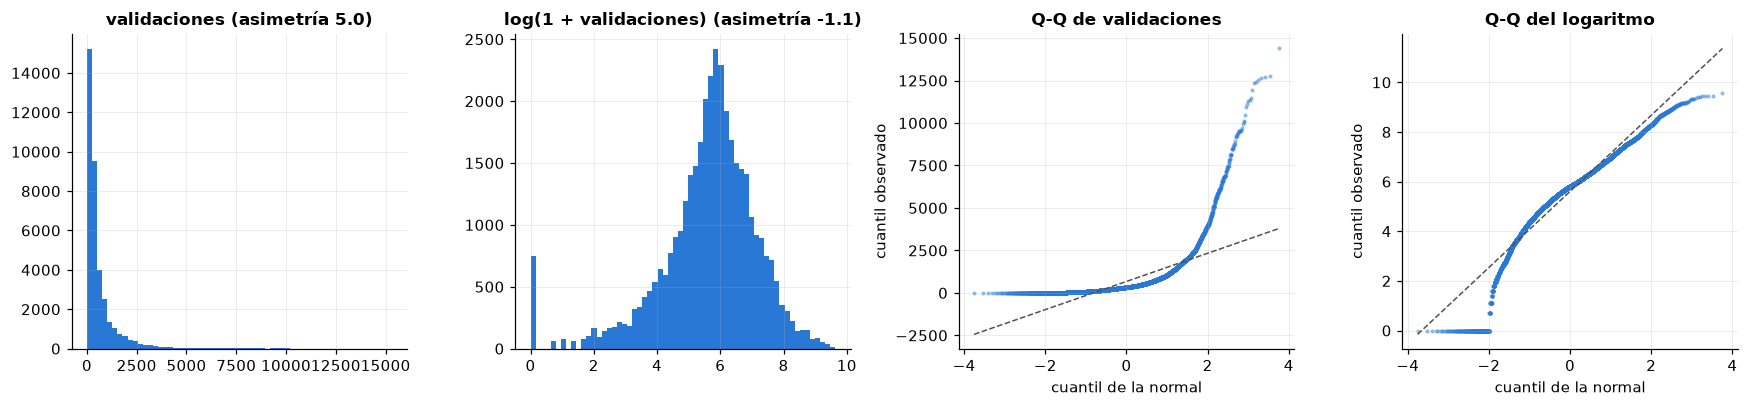

,asimetría,curtosis (exceso)
validaciones,4.99,34.95
log(1 + validaciones),-1.08,2.36


In [27]:
# QUÉ HACE: revisa si la variable objetivo es normal y si el logaritmo ayuda, para decidir si Pearson es confiable.
# CÓMO: histogramas de validaciones y de log(1 + validaciones) con su asimetría y curtosis, más el gráfico cuantil-cuantil contra la normal (si los puntos siguen la diagonal, es normal).
# QUÉ MIRAR: la variable original tiene cola muy larga (asimetría 3-5); el logaritmo la acerca a una campana pero no la vuelve normal (hay un montón de valores pequeños).
from scipy import stats
yy = base['validaciones'].astype(float); yl = base['y_log']
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
axes[0].hist(yy, bins=60, color=COL['hábil']); axes[0].set_title(f'validaciones (asimetría {yy.skew():.1f})')
axes[1].hist(yl, bins=60, color=COL['hábil']); axes[1].set_title(f'log(1 + validaciones) (asimetría {yl.skew():.1f})')
for ax, d, t in [(axes[2], yy, 'Q-Q de validaciones'), (axes[3], yl, 'Q-Q del logaritmo')]:
    (osm, osr), (pend, inter, _) = stats.probplot(d.sample(8000, random_state=1), dist='norm')
    ax.scatter(osm, osr, s=3, color=COL['hábil'], alpha=0.4); ax.plot(osm, pend * osm + inter, color='#52514e', lw=1, ls='--')
    ax.set_title(t); ax.set_xlabel('cuantil de la normal'); ax.set_ylabel('cuantil observado')
plt.tight_layout(); plt.savefig(FIGS / '03_normalidad_objetivo.png', bbox_inches='tight'); plt.show()
pd.DataFrame({'asimetría': [yy.skew(), yl.skew()], 'curtosis (exceso)': [yy.kurt(), yl.kurt()]}, index=['validaciones', 'log(1 + validaciones)']).round(2)

,Pearson (originales),Pearson (con logaritmo),Spearman,pares usados
lag_1,1.00,0.99,0.99,32184
media_hist,0.99,0.95,0.97,34866
val_dia,0.61,0.60,0.60,37548
sistema_hora,0.32,0.50,0.41,37548
pct_alimentacion,0.47,0.30,0.29,37548
hora,-0.19,-0.27,-0.24,37548
km_centro,0.17,0.10,0.10,34020
pct_tarifa2,0.04,0.10,0.08,37548
pct_manana,0.12,-0.07,-0.05,37548
vagones,-0.08,-0.00,0.03,34020


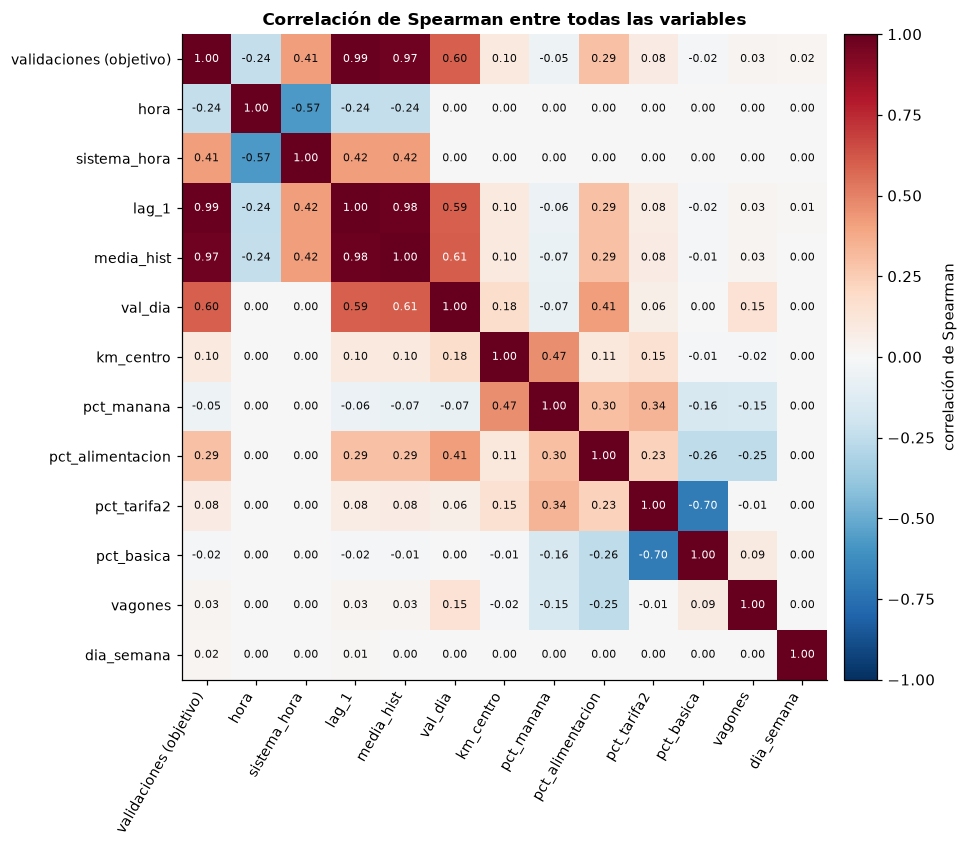

In [28]:
# QUÉ HACE: calcula la correlación de cada variable candidata con la variable objetivo de tres formas (Pearson con los datos originales, Pearson con logaritmos y Spearman) y dibuja la matriz de Spearman entre todas las variables.
# CÓMO: Pearson mide relación lineal; Spearman usa rangos (no se afecta por el logaritmo ni por valores extremos); pares con datos faltantes se omiten por pareja.
# QUÉ MIRAR: el historial (media_hist, lag_1) y el tamaño de la estación (val_dia) muy por encima del resto; la hora correlaciona poco (-0,24) porque su relación con la demanda no es una recta (sube, baja, sube y baja) y sistema_hora la recoge mejor; si Pearson y Spearman difieren mucho (p. ej. pct_manana), hay colas largas o curvas.
def col_log(v): return v + '_log' if v in LOGS else v
res = pd.DataFrame({'Pearson (originales)': [base['validaciones'].corr(base[v]) for v in VARS],
                    'Pearson (con logaritmo)': [base['y_log'].corr(base[col_log(v)]) for v in VARS],
                    'Spearman': [base['validaciones'].corr(base[v], method='spearman') for v in VARS],
                    'pares usados': [int(base[['validaciones', v]].dropna().shape[0]) for v in VARS]}, index=VARS)
res = res.reindex(res['Spearman'].abs().sort_values(ascending=False).index)
display(res.round(2))

M = base[['validaciones'] + VARS].corr(method='spearman')
nombres = ['validaciones (objetivo)'] + VARS
fig, ax = plt.subplots(figsize=(9.5, 7.8))
im = ax.imshow(M.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(M))); ax.set_xticklabels(nombres, rotation=60, ha='right', fontsize=9); ax.set_yticks(range(len(M))); ax.set_yticklabels(nombres, fontsize=9); ax.grid(False)
for a, b in itertools.product(range(len(M)), repeat=2):
    ax.text(b, a, f"{M.values[a, b]:.2f}", ha='center', va='center', fontsize=7.5, color='white' if abs(M.values[a, b]) > 0.6 else '#0b0b0b')
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).set_label('correlación de Spearman')
ax.set_title('Correlación de Spearman entre todas las variables')
plt.tight_layout(); plt.savefig(FIGS / '03_correlaciones_spearman.png', bbox_inches='tight'); plt.show()

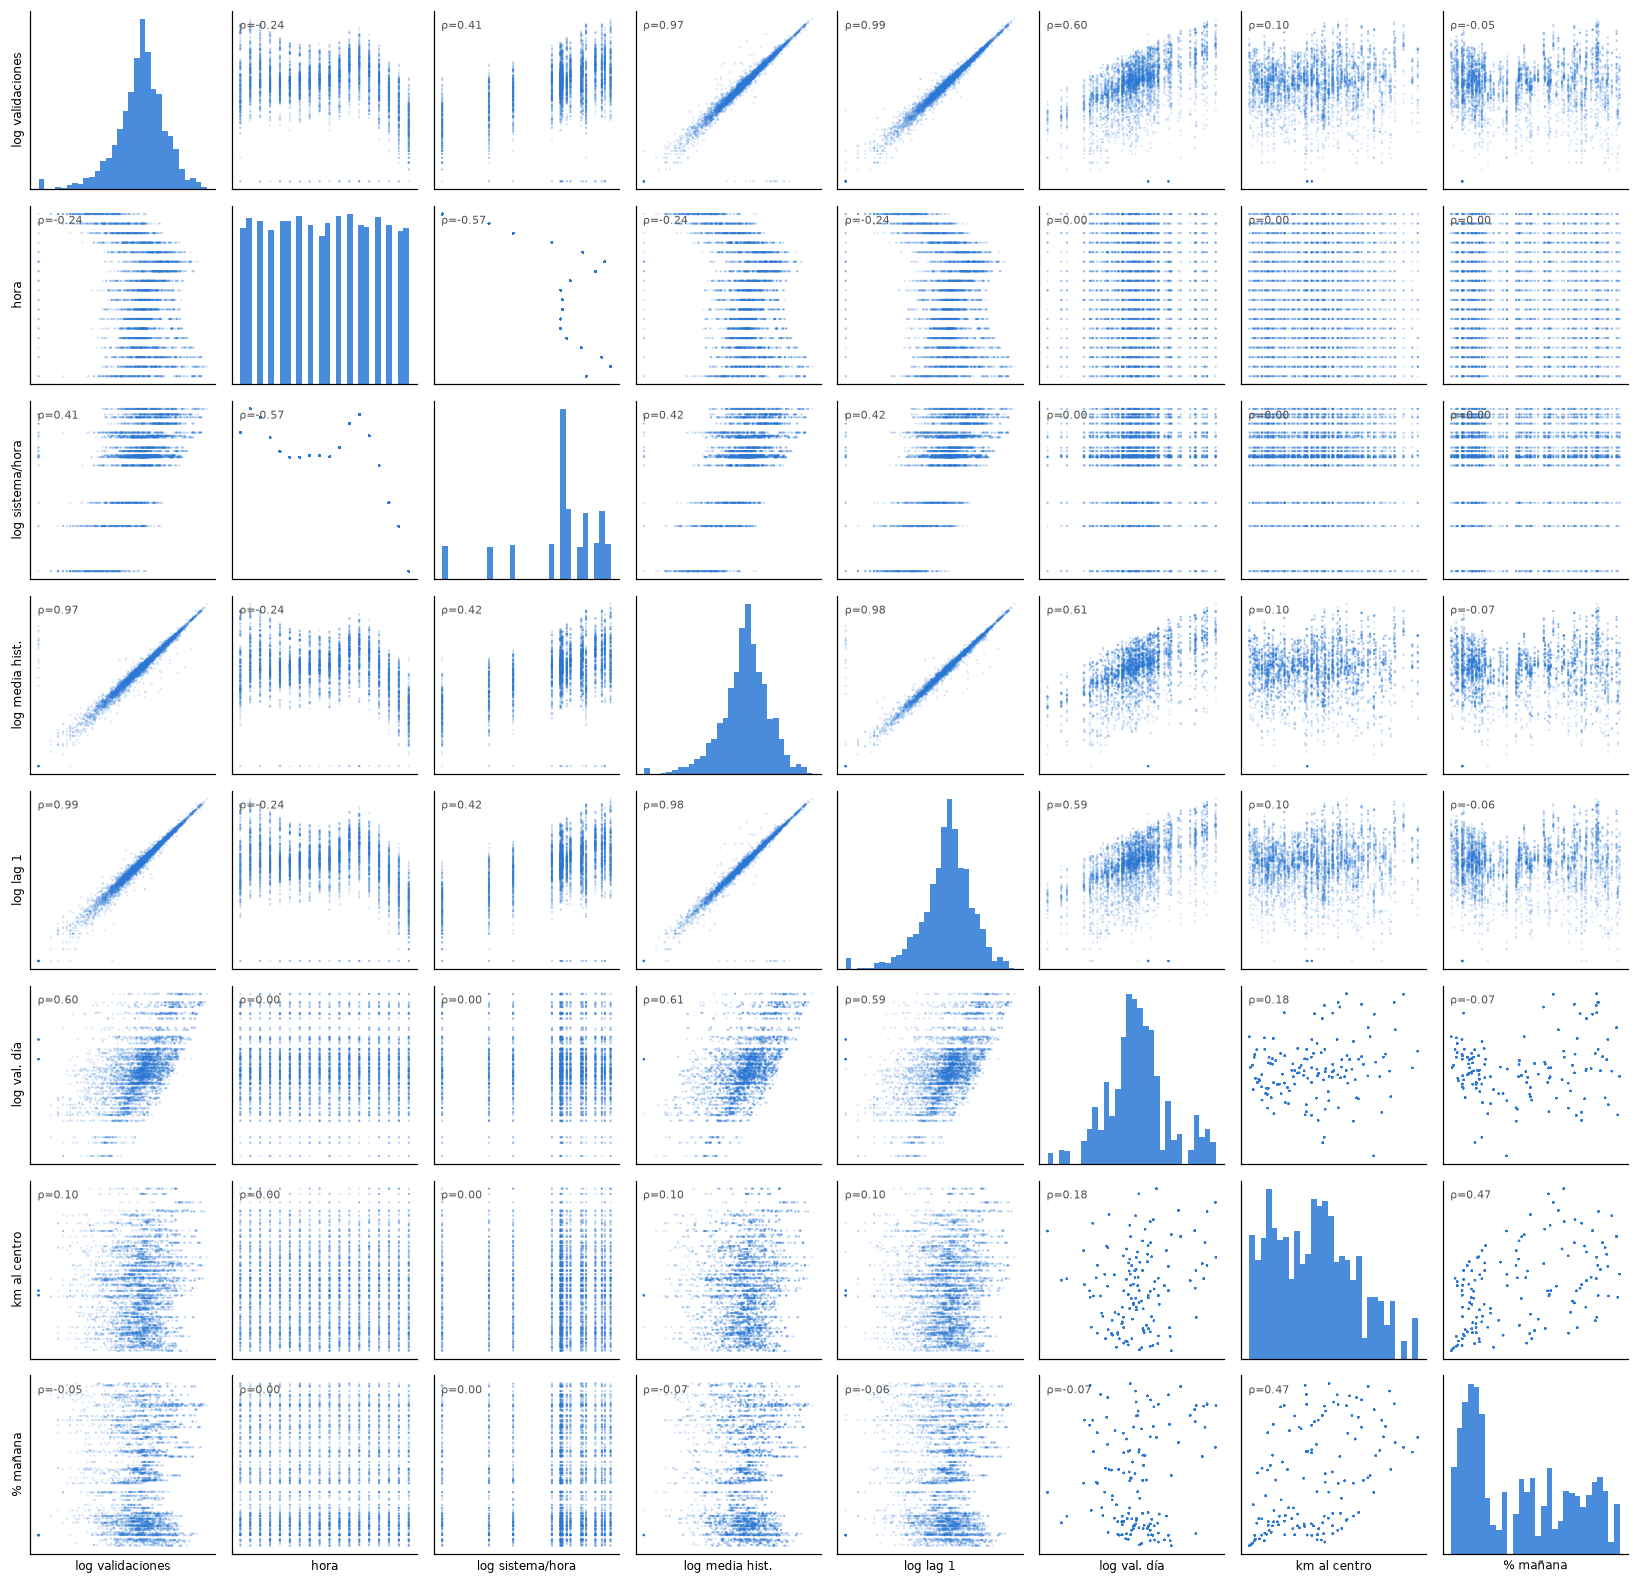

In [29]:
# QUÉ HACE: dibuja las dispersiones de todo contra todo (matplotlib) para 8 variables, con el histograma de cada una en la diagonal.
# CÓMO: 6.000 filas al azar; los conteos van en logaritmo para que las nubes no queden aplastadas contra el eje; cada panel es una pareja de variables.
# QUÉ MIRAR: la relación casi lineal del objetivo con media_hist, lag_1 y val_dia (en logaritmo); la curva doble de la hora; que km_centro y pct_manana se relacionan entre sí (periferia = mañana) y casi no con el nivel de demanda.
vs = [('y_log', 'log validaciones'), ('hora', 'hora'), ('sistema_hora_log', 'log sistema/hora'), ('media_hist_log', 'log media hist.'),
      ('lag_1_log', 'log lag 1'), ('val_dia_log', 'log val. día'), ('km_centro', 'km al centro'), ('pct_manana', '% mañana')]
mu = base.dropna(subset=[v for v, _ in vs]).sample(6000, random_state=7)
k = len(vs)
fig, axes = plt.subplots(k, k, figsize=(15, 14.5))
for r, (vr, nr) in enumerate(vs):
    for c, (vc, nc) in enumerate(vs):
        ax = axes[r, c]; ax.grid(False)
        if r == c:
            ax.hist(mu[vr], bins=30, color=COL['hábil'], alpha=0.85)
        else:
            ax.scatter(mu[vc], mu[vr], s=2, color=COL['hábil'], alpha=0.18, edgecolors='none')
            ax.text(0.04, 0.9, f"ρ={base[vc].corr(base[vr], method='spearman'):.2f}", transform=ax.transAxes, fontsize=7.5, color='#52514e')
        ax.set_xticks([]); ax.set_yticks([])
        if r == k - 1: ax.set_xlabel(nc, fontsize=8)
        if c == 0: ax.set_ylabel(nr, fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / '03_matriz_dispersion.png', bbox_inches='tight', dpi=100); plt.show()

In [30]:
# QUÉ HACE: muestra varianzas y covarianzas (en logaritmo, para variables de conteo) y descompone la variación de la variable objetivo: cuánto explican la estación, la hora y su combinación.
# CÓMO: la covarianza entre dos variables depende de sus unidades, por eso se compara mejor la correlación (= covarianza / (desv. x desv. y)); el "% de la varianza explicada" es el cociente entre la varianza de los promedios del grupo y la varianza total (eta cuadrado) de log(1 + validaciones).
# QUÉ MIRAR: la estación sola explica una parte grande, la hora otra, y la combinación estación x hora casi todo; lo que sobra es la variación día a día.
sel = ['y_log', 'media_hist_log', 'lag_1_log', 'val_dia_log', 'sistema_hora_log', 'km_centro']
sub = base[sel].dropna()
varz = sub.var().rename('varianza').to_frame().T
print('Varianzas (en logaritmo, salvo km_centro):'); display(varz.round(2))
cov = sub.cov(); print('Matriz de covarianzas:'); display(cov.round(2))
print(f"Chequeo: cov(objetivo, media_hist) / (desv_x * desv_y) = {cov.loc['y_log', 'media_hist_log'] / np.sqrt(cov.loc['y_log', 'y_log'] * cov.loc['media_hist_log', 'media_hist_log']):.3f} = correlación de Pearson {sub['y_log'].corr(sub['media_hist_log']):.3f}")

def eta2(claves, d):
    medias = d.groupby(claves)['y_log'].transform('mean')
    return 1 - ((d['y_log'] - medias) ** 2).sum() / ((d['y_log'] - d['y_log'].mean()) ** 2).sum()
def eta2_aditivo(d):
    r = d['y_log'] - d.groupby('cod_estacion')['y_log'].transform('mean')
    return 1 - ((r - r.groupby(d['hora']).transform('mean')) ** 2).sum() / ((d['y_log'] - d['y_log'].mean()) ** 2).sum()
def descomposicion(d):
    return pd.Series({'solo la hora': eta2(['hora'], d), 'solo la estación': eta2(['cod_estacion'], d), 'estación + hora (aditivo)': eta2_aditivo(d),
                      'estación x hora': eta2(['cod_estacion', 'hora'], d), 'estación x hora x día de la semana': eta2(['cod_estacion', 'hora', 'dia_semana'], d),
                      'estación x hora x fecha (todo)': eta2(['cod_estacion', 'hora', 'fecha'], d)})
expl = pd.DataFrame({'todas las estaciones': descomposicion(base), 'sin las que cambian de régimen': descomposicion(base[~base['cambia_regimen']])}) * 100
expl.index.name = '% de la varianza de log(1 + validaciones) explicada por'
expl.round(1)

Varianzas (en logaritmo, salvo km_centro):


,y_log,media_hist_log,lag_1_log,val_dia_log,sistema_hora_log,km_centro
varianza,1.94,1.85,1.98,0.68,0.65,20.91


Matriz de covarianzas:


,y_log,media_hist_log,lag_1_log,val_dia_log,sistema_hora_log,km_centro
y_log,1.94,1.82,1.94,0.61,0.62,0.63
media_hist_log,1.82,1.85,1.85,0.62,0.63,0.59
lag_1_log,1.94,1.85,1.98,0.61,0.64,0.61
val_dia_log,0.61,0.62,0.61,0.68,0.00,0.70
sistema_hora_log,0.62,0.63,0.64,0.00,0.65,-0.00
km_centro,0.63,0.59,0.61,0.70,-0.00,20.91


Chequeo: cov(objetivo, media_hist) / (desv_x * desv_y) = 0.958 = correlación de Pearson 0.958


,todas las estaciones,sin las que cambian de régimen
% de la varianza de log(1 + validaciones) explicada por,,
solo la hora,26.8,37.1
solo la estación,45.4,39.3
estación + hora (aditivo),72.2,76.3
estación x hora,88.6,98.2
estación x hora x día de la semana,89.4,99.0
estación x hora x fecha (todo),100.0,100.0


In [31]:
# QUÉ HACE: itera: quita lo que explican la estación y la hora (el "patrón normal" de cada estación-hora) y mira qué se relaciona con lo que queda, la variación día a día.
# CÓMO: residuo = log(1 + validaciones) menos el promedio (en logaritmo) de su estación-hora; se excluyen las estaciones que abren o cierran entre agosto y septiembre (su residuo sería el cambio de régimen, no la variación diaria); luego se mide el efecto común del día, el efecto del día de la semana y si el residuo se parece al de ayer.
# QUÉ MIRAR: el residuo es pequeño frente a la variación original; una parte es común a todo el sistema y sigue un patrón semanal (lunes más bajo, jueves y viernes más altos); el residuo de ayer ayuda poco a explicar el de hoy.
rb = base[~base['cambia_regimen']].copy()
rb['resid'] = rb['y_log'] - rb.groupby(['cod_estacion', 'hora'])['y_log'].transform('mean')
gg = rb.groupby(['cod_estacion', 'hora'])
rb['resid_lag'] = gg['resid'].shift(1)
rb.loc[(rb['fecha_dt'] - gg['fecha_dt'].shift(1)).dt.days > 4, 'resid_lag'] = np.nan
dia = rb.groupby('fecha')['resid'].mean()
ss_tot = (rb['resid'] ** 2).sum(); ss_dia = (rb['fecha'].map(dia) ** 2).sum()
sem = rb.groupby('dia_semana')['resid'].mean(); ss_sem = (rb['dia_semana'].map(sem) ** 2).sum()
tabla = pd.Series({'desviación estándar de log(1 + validaciones)': rb['y_log'].std(), 'desviación estándar del residuo (sin estación x hora)': rb['resid'].std(),
                   '% del residuo que es efecto común del día': ss_dia / ss_tot * 100, '% del residuo que explica el día de la semana': ss_sem / ss_tot * 100,
                   'correlación del residuo con el de ayer (Pearson)': rb['resid'].corr(rb['resid_lag'])}, name='valor')
display(tabla.round(3).to_frame())
efecto = pd.DataFrame({'efecto del día (log)': dia.round(3), 'día': calendario.loc[pd.to_datetime(dia.index), 'día'].values,
                       'validaciones del sistema': dh.loc[pd.to_datetime(dia.index)].sum(axis=1).values.astype(int)}, index=dia.index)
display(efecto.T)
print('Efecto promedio por día de la semana (log; 0,05 = 5 % más que lo normal de la estación-hora):')
pd.DataFrame({'efecto (log)': sem.round(3).values, '% aprox.': ((np.exp(sem) - 1) * 100).round(1).values}, index=['lunes', 'martes', 'miércoles', 'jueves', 'viernes']).T

,valor
desviación estándar de log(1 + validaciones),1.355
desviación estándar del residuo (sin estación x hora),0.180
% del residuo que es efecto común del día,4.668
% del residuo que explica el día de la semana,4.035
correlación del residuo con el de ayer (Pearson),0.152


fecha,2026-08-03,2026-08-04,2026-08-05,2026-08-06,2026-08-10,2026-08-11,2026-08-12,2026-08-13,2026-08-14,2026-09-14,2026-09-15,2026-09-16,2026-09-17,2026-09-18
efecto del día (log),-0.05,0.006,0.024,0.039,-0.084,-0.028,-0.006,0.001,0.044,-0.049,0.0,0.024,0.024,0.056
día,lunes,martes,miércoles,jueves,lunes,martes,miércoles,jueves,viernes,lunes,martes,miércoles,jueves,viernes
validaciones del sistema,1817358,1879861,1893706,1837051,1751957,1832549,1852058,1837159,1827777,1841024,1896950,1924867,1878857,1860400


Efecto promedio por día de la semana (log; 0,05 = 5 % más que lo normal de la estación-hora):


,lunes,martes,miércoles,jueves,viernes
efecto (log),-0.061,-0.007,0.014,0.021,0.05
% aprox.,-5.900,-0.700,1.400,2.100,5.10


### Lectura de la sección 8

**La tabla de trabajo.** 37.548 filas (149 estaciones activas x 14 días x 18 horas). **Cinco estaciones cambian de régimen** entre agosto y septiembre: Calle 72 - Areandina (abre en septiembre), Calle 76 (cierra) y Tibanica - Primavera, Los Laureles e Islandia (abren). Son pocas, pero **distorsionan** cualquier comparación entre tandas de días; por eso se marcan (`cambia_regimen`) y varios análisis se hacen con y sin ellas.

**Normalidad.** La variable objetivo está lejos de ser normal: asimetría 5,0 y curtosis en exceso 35 (cola muy larga). Con logaritmo mejora (asimetría -1,1; curtosis 2,4) pero **no queda normal** (hay un grupo de ceros y una cola hacia abajo). Conclusión: **Pearson sobre los datos originales no es confiable**; se usa **Spearman** (rangos) y Pearson sobre logaritmos como comparación. Se nota la fragilidad: `pct_manana` pasa de +0,12 a -0,07 y `pct_alimentacion`, de 0,47 a 0,30 al tomar logaritmos.

**Correlación con la variable objetivo (Spearman).**

| Variable | Spearman | Lectura |
|---|---|---|
| `lag_1` (día hábil anterior) | 0,99 | casi idéntica: *lleva el nivel* de la estación-hora |
| `media_hist` (promedio de días anteriores) | 0,97 | ídem |
| `val_dia` (tamaño de la estación) | 0,60 | las estaciones grandes tienen más demanda en cualquier hora (con fuga: usa los 14 días) |
| `sistema_hora` (demanda total del sistema en esa hora) | 0,41 | recoge la forma del día |
| `pct_alimentacion` | 0,29 | portales: entrada en oleadas |
| `hora` | -0,24 | débil por no ser una recta |
| resto (`km_centro`, `pct_tarifa2`, `pct_manana`, `vagones`, `dia_semana`, `pct_basica`) | entre -0,05 y 0,10 | casi nada **por sí solas** |

Entre las variables explicativas: `pct_tarifa2` y `pct_basica` tienen **-0,70** (casi mecánico: la tullave Básica no tiene tarifa 2; no deben entrar juntas sin cuidado), `km_centro` y `pct_manana` 0,47 (periferia = mañana) y `pct_alimentacion` con `val_dia` 0,41 (los portales son grandes y reciben por alimentación).

**Que el historial correlacione 0,99 no es un gran logro:** solo dice que cada estación-hora tiene su propio nivel. La pregunta útil es qué queda después de quitar ese nivel.

**Varianzas y covarianzas.** En logaritmo, la varianza del objetivo es 1,94 y su covarianza con `media_hist` es 1,82: dividiendo por las desviaciones se obtiene exactamente la correlación (0,958). La covarianza **depende de las unidades** (`km_centro` tiene varianza 20,9), por eso para comparar variables se usa la correlación.

**¿Cuánto explican la estación, la hora y su combinación?** (sin las estaciones que cambian de régimen)

| Se explica por | % de la varianza |
|---|---|
| solo la hora | 37 % |
| solo la estación | 39 % |
| estación + hora (efectos sumados) | 76 % |
| **estación x hora** | **98,2 %** |
| estación x hora x día de la semana | 99,0 % |

Lo que importa es la **combinación**: el "dónde" y el "cuándo" no se suman, interactúan (cada estación tiene su propia curva horaria). Con las cinco estaciones que cambian, el valor baja a 88,6 %: es el costo de ignorar los cambios de red.

**Iteración: la variación día a día.** Quitado el patrón estación-hora, el residuo tiene desviación 0,18 (frente a 1,36 de la variable original). De ese residuo, **4,7 % es un efecto común a todo el sistema** en el día y **4,0 % lo explica el día de la semana**: los lunes quedan entre un 5 % y un 8 % por debajo de lo normal y los viernes entre un 4 % y un 6 % por encima. La correlación del residuo con el de ayer es solo 0,15: **lo que pasó ayer por encima o por debajo de lo normal ayuda poco** a explicar hoy.

**Qué significa para el modelo.** (1) Un modelo que solo repita el promedio de la estación-hora ya explica ~98 %: **ese es el piso a superar** y es lo que el modelo debe batir. (2) Lo que sobra es pequeño y tiene dos componentes: día de la semana y un nivel común del día. (3) Las variables que de verdad pueden aportar son el **historial de la estación-hora**, la **hora**, el **día de la semana** y atributos de la estación. (4) `val_dia` y cualquier cálculo con los 14 días **no se pueden usar** como predictores (fuga).

## 9. De los patrones a las hipótesis y a la pregunta analítica

Con lo visto en las secciones 2 a 8 se cierra el EDA: qué se sabe, qué hipótesis quedan para el modelo y cuál es la pregunta analítica definitiva. Antes, un dato concreto para la pregunta guía: **¿cuántas estaciones y horas superan cierto nivel de demanda?** El umbral exacto en que se necesita personal **no está en los datos** (hay que definirlo con la operación); aquí solo se muestra cómo cambia el resultado con distintos umbrales.

In [32]:
# QUÉ HACE: cuenta en cuántas estaciones y horas de un día hábil típico la demanda supera distintos umbrales de validaciones por hora, y en qué franja ocurre.
# CÓMO: usa la demanda promedio de cada estación activa en cada hora (5:00-22:59) y cuenta las celdas que superan el umbral; "% de las validaciones dentro" es la parte de la demanda del día que cae en esas celdas.
# QUÉ MIRAR: con 1.000 validaciones por hora son unas 450 celdas (95 estaciones) que reúnen 60 % de la demanda; con 4.000 son solo ~50 celdas y casi todas en la punta de la mañana; la tarde tiene más estaciones por encima de 1.000 que la mañana.
f = por_est_hora.loc[act, 5:22]
filas = []
for u in [500, 1000, 2000, 4000]:
    m = f >= u
    filas.append({'umbral (validaciones por hora)': u, 'celdas estación-hora': int(m.values.sum()), 'estaciones distintas': int(m.any(axis=1).sum()),
                  '% de las validaciones dentro': f.where(m).sum().sum() / f.values.sum() * 100,
                  'punta mañana (5-8 h)': int(m.loc[:, 5:8].values.sum()), 'valle (9-15 h)': int(m.loc[:, 9:15].values.sum()),
                  'punta tarde (16-19 h)': int(m.loc[:, 16:19].values.sum()), 'noche (20-22 h)': int(m.loc[:, 20:22].values.sum())})
umbrales = pd.DataFrame(filas).set_index('umbral (validaciones por hora)')
display(umbrales.round(1))
m1000 = (f >= 1000)
print('Estaciones por encima de 1.000 validaciones por hora, hora a hora:')
m1000.sum().rename('estaciones').to_frame().T

,celdas estación-hora,estaciones distintas,% de las validaciones dentro,punta mañana (5-8 h),valle (9-15 h),punta tarde (16-19 h),noche (20-22 h)
umbral (validaciones por hora),,,,,,,
500,941,129,79.7,235,357,333,16
1000,456,95,60.5,126,148,182,0
2000,177,48,38.6,80,38,59,0
4000,54,18,20.2,43,2,9,0


Estaciones por encima de 1.000 validaciones por hora, hora a hora:


hora,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
estaciones,23,39,39,25,19,17,17,20,21,22,32,57,70,43,12,0,0,0


### Hallazgos del EDA

| # | Hallazgo | Sección |
|---|---|---|
| 1 | El día hábil es un régimen propio: sábado ~62 %, domingo y festivo ~30 % de un hábil, y con otra forma de curva (dos picos solo en hábiles). | 2-3 |
| 2 | Un día hábil se parece mucho a otro: la variación entre días en la misma hora es de 2-5 % del promedio. | 3 |
| 3 | La demanda es un **conteo muy asimétrico** (mediana 317, promedio 653, máximo 15.308 por estación-hora) y con más varianza que un Poisson. | 4 |
| 4 | **27 de 154 estaciones reúnen la mitad** de las validaciones (Gini 0,48); las más grandes son portales y cabeceras. | 4 |
| 5 | Las estaciones se dividen en "de mañana" (57; periferia y portales), "de tarde" (72; centro y norte) y "doble pico" (20). | 4, 6 |
| 6 | Los portales reciben 60-85 % por **alimentación** (oleadas de buses zonales); el resto de las estaciones, casi nada. | 4 |
| 7 | La mezcla de usuarios casi no cambia entre punta y valle; el cobro $0 (tarifa 2) está en estaciones puntuales y baja en la tarde. | 5 |
| 8 | **La punta de la mañana concentra la carga en pocos puntos** (portales, 7-10 mil por hora); la **de la tarde está más repartida** (máximo 5,4 mil en Calle 100). | 6 |
| 9 | **No todos vuelven en TransMilenio:** 52 % de quienes entran en la punta de la mañana vuelve a validar en la tarde; el flujo es periferia -> centro (mañana) y centro -> periferia (tarde); el destino dominante es Calle 100. | 7 |
| 10 | El 10 % de las tarjetas (habituales, 12-14 días) hace el 32 % de las validaciones. | 7 |
| 11 | **La combinación estación x hora explica ~98 %** de la variación (en logaritmo); lo que sobra es un efecto del día de la semana (lunes bajo, viernes alto) y un nivel común del día. | 8 |
| 12 | Cinco estaciones abren o cierran entre agosto y septiembre: cambian el nivel y complican la validación temporal. | 8 |

### Hipótesis

| # | Hipótesis | Evidencia | Qué se hace con ella |
|---|---|---|---|
| H1 | La demanda de una estación-hora en un día hábil es **muy predecible con su propio historial**. | Hallazgos 2 y 11. | Línea base: promedio histórico de la estación-hora. Es lo que el modelo debe superar. |
| H2 | **El día de la semana** aporta una mejora pequeña pero real (lunes -5 a -8 %, viernes +4 a +6 %). | Sección 8 (iteración). | Variable `dia_semana`; se prueba si mejora frente a la línea base. |
| H3 | Los **portales** tienen presión en oleadas por alimentación, no continua. | Hallazgo 6. | Características `pct_alimentacion` y accesos activos; análisis aparte de los portales. |
| H4 | La **demanda de la tarde en el centro** depende de lo que entró por la mañana en los portales de origen. | Hallazgo 9. | Se contrasta en el modelo (variable: entradas de la mañana en los orígenes del flujo). |
| H5 | El **perfil de usuario** no explica cuándo hay presión (mezcla estable). | Hallazgo 7. | No entra como predictor principal; sí `pct_tarifa2`/`pct_basica` como atributos de estación (sin usarlos juntos). |
| H6 | Los **cambios de red** (estaciones nuevas, cerradas o temporales) rompen la validación temporal. | Hallazgo 12. | Se marcan y se evalúa el modelo con y sin ellas; en el flujo de Prefect hay que detectarlas. |
| H7 | La **hora de alta presión** (por encima de un umbral) se concentra en pocas estaciones-hora y es más extrema en la mañana. | Tabla de umbrales y hallazgo 8. | Se define el umbral con la operación y se evalúa el modelo también como clasificación (¿hora de alta presión?). |

### Pregunta analítica definitiva

> **¿Qué estaciones de la troncal de TransMilenio requieren refuerzo de personal de apoyo para ordenar el ingreso de usuarios, según su demanda por franja horaria?**

**Objetivo general:** identificar y anticipar, con el historial de días anteriores, las estaciones con mayor demanda de ingreso en cada franja horaria, para orientar el refuerzo del personal de apoyo que ordena el ingreso de usuarios.

**Objetivos específicos:**
1. Describir cómo se distribuye la demanda de ingreso a lo largo de la semana y del día, y justificar el análisis solo con días hábiles.
2. Ordenar las estaciones y franjas por demanda y definir, con la operación, el umbral de alta presión (punto de partida: 1.000 validaciones por hora).
3. Construir un modelo que anticipe la demanda por estación y hora y compararlo con el promedio histórico mediante validación temporal.
4. Entregar a la gerencia un ranking de estaciones y franjas y un tablero; el margen de incertidumbre del pico se reporta en el notebook 04.

- **Unidad de análisis:** estación x día x hora (en días hábiles).
- **Variable objetivo:** `validaciones` (conteo); y su versión binaria "hora de alta presión" (validaciones por encima de un umbral definido con la operación).
- **Predictores permitidos:** historial de la misma estación-hora (`lag_1`, `media_hist`), hora, día de la semana, demanda del sistema en esa hora y atributos de la estación que no usen el mismo día (tipo, `% alimentación`, forma del día, distancia al centro). **Prohibido:** cualquier medida calculada con el día que se predice (`val_dia` de los mismos 14 días, por ejemplo).
- **Modelo:** regresión (conteo) con **línea base** = promedio histórico de la estación-hora; Random Forest y LightGBM (y una regresión de conteos como referencia); métricas MAE, WAPE y RMSE; **validación temporal** (entrenar con unos días y probar con días posteriores, nunca mezclar al azar). Si no supera la línea base por un margen útil, **se dice** y la línea base queda como respuesta.
- **Producto para la gerencia:** ranking de estaciones y horas con mayor probabilidad de alta presión, para decidir **dónde y cuándo** poner personal de apoyo, y un tablero con el resultado.

### Información adicional necesaria (punto c de la rúbrica)

| Información | Estado | Para qué serviría |
|---|---|---|
| Calendario de festivos | Usado (1 festivo en el periodo) | Separar días hábiles de festivos |
| Coordenadas de estaciones | Faltan 14 estaciones activas (8,7 % de las validaciones) | Mapa y distancia al centro |
| Aperturas, cierres y estaciones temporales | No hay un archivo; se infiere de los datos (5 casos) | Evitar mezclar regímenes |
| Eventos masivos, obras, paros, clima | No disponible | Explicar días atípicos |
| Capacidad y frecuencia de buses, ocupación | No disponible | Pasar de "validaciones" a "aglomeración" |
| Datos del servicio zonal | Fuera del alcance (solo troncal) | Entender las oleadas de alimentación |

### Limitaciones

- **Solo 14 días hábiles** en tres semanas separadas por un mes; no se ve estacionalidad larga ni efectos de calendario más allá de un festivo.
- La "necesidad de personal" **no se observa**: se infiere de la demanda con un umbral.
- Las validaciones miden **entradas**, no la gente que está dentro de la estación ni las filas reales.
- El destino de los viajes es inferido; no hay transbordos internos ni otros medios.

**Siguiente paso:** el notebook 04 (ranking de estaciones y personal de apoyo); el Teorema del Límite Central con la hora de validación queda como anexo; luego el flujo con Prefect y Dask que construye la tabla de la unidad de análisis, su carga a AWS (solo resultados) y el modelo.